# DASH4D gut microbiome visualization

## Setup and intermediate inputs

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.patches import Patch
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from functools import reduce
import textwrap
from matplotlib.patches import Polygon

import os
import re
import warnings
import sys
import platform
from importlib.metadata import version

In [2]:
print(sys.version)

3.10.18 | packaged by conda-forge | (main, Jun  4 2025, 14:46:00) [Clang 18.1.8 ]


In [3]:
from pathlib import Path

# Both the microbiome and SCFA analysis Rmd scripts write to these folders.
# Paths are relative to the notebook's current working directory.
INTERMEDIATE_ROOT = Path("../intermediate")
INTERMEDIATE_MICRO = INTERMEDIATE_ROOT / "microbiome"
INTERMEDIATE_SCFA = INTERMEDIATE_ROOT / "SCFA"

# Retain DATA as an alias for existing plotting code.
DATA = INTERMEDIATE_MICRO
PAPER_FIG = Path("../figures")
PAPER_FIG.mkdir(parents=True, exist_ok=True)


### Check required intermediate files

This optional preflight cell checks that every input for the **numbered** figures exists. The files are produced by the microbiome/SCFA R Markdown analyses; no raw `data/` files are read directly by this notebook. If any files are missing, rerun their generating Rmd chunks or correct `INTERMEDIATE_ROOT` above.


In [4]:
# Inputs for Figures 1–3 and S3–S10, grouped by analysis output folder.
MICROBIOME_INPUTS = [
    "CLR_changefrombaseline_PCA_long.tsv",
    "DASH4D_DA_all_prev_rl.tsv",
    *[f"{gene}_{kind}.tsv" for gene in ("but", "EtfA", "EtfB")
      for kind in ("gene_DASH_effect", "gene_contri_data")],
    "ind_covariates_jaccard_comp_df.tsv",
    "ind_covariates_bc_comp_df.tsv",
    "ind_covariates_aitchison_comp_df.tsv",
    "DASH4D_p005_all_prev_rl.tsv",
    *[f"{period}_feature_{outcome}_marginal.tsv"
      for period in ("baseline", "change")
      for outcome in ("SBP", "DBP", "fasting_glucose", "fructosamine", "log_HOMA_IR")],
    "change_SBP_baselinemicrogp3_df.tsv",
    "change_fructosamine_baselinemicrogp3_df.tsv",
    "change_fb_glucose_baselinemicrogp3_df.tsv",
    "change_log_HOMA_IR_baselinemicrogp3_df.tsv",
]
SCFA_INPUTS = [
    f"{specimen}_scfa_results_{comparison}.tsv"
    for specimen in ("fecal", "plasma")
    for comparison in ("DASH", "sodium")
]

required_inputs = ([INTERMEDIATE_MICRO / name for name in MICROBIOME_INPUTS]
                   + [INTERMEDIATE_SCFA / name for name in SCFA_INPUTS])
missing_inputs = [path for path in required_inputs if not path.is_file()]
print(f"Found {len(required_inputs) - len(missing_inputs)}/{len(required_inputs)} required intermediate inputs.")
if missing_inputs:
    print("Missing intermediate files (generate them using the Rmd analyses):")
    for path in missing_inputs:
        print("  -", path)


Found 30/30 required intermediate inputs.


### Figure 1

In [5]:
## load the PCA ordination data
PCA_changefrombaseline_long = pd.read_csv(f"{DATA}/CLR_changefrombaseline_PCA_long.tsv", sep='\t')

In [6]:
PCA_changefrombaseline_width = PCA_changefrombaseline_long.pivot_table(
    index=['pptid', 'DASH', 'diet', 'visit'],
    columns='PC',
    values='value'
).reset_index()

In [7]:
PCA_changefrombaseline_width

PC,pptid,DASH,diet,visit,PC1,PC2
0,D0007THJO,Comparison diet,CL,FP1,-0.005481,-0.032095
1,D0007THJO,DASH4D diet,DH,FP2,0.027499,-0.006508
2,D0011MCAU,Comparison diet,CH,FP2,0.008688,0.023020
3,D0011MCAU,Comparison diet,CL,FP4,0.010638,0.029453
4,D0011MCAU,DASH4D diet,DH,FP3,0.000730,0.017561
...,...,...,...,...,...,...
339,D2118GILI,DASH4D diet,DL,FP3,0.016601,0.002865
340,D2249FERE,Comparison diet,CH,FP4,-0.026337,-0.015232
341,D2249FERE,Comparison diet,CL,FP3,-0.023928,-0.014096
342,D2249FERE,DASH4D diet,DH,FP2,0.007661,-0.038249


In [8]:
PCA_changefrombaseline_width['DASH_ord_x'] = -0.1
PCA_changefrombaseline_width.loc[
    PCA_changefrombaseline_width['DASH'] == 'DASH4D diet',
    'DASH_ord_x'] = 0.1


PCA_changefrombaseline_width['DASH_ord_y'] = 0.1
PCA_changefrombaseline_width.loc[
    PCA_changefrombaseline_width['DASH'] == 'DASH4D diet',
    'DASH_ord_y'] = -0.1

In [9]:
## function to format the taxa
def format_italic_taxa(raw_label):
    """
    Transforms 'f__Lachnospiraceae; s__Acetatifactor sp900066365' 
    into 'Lachnospiraceae: $\mathit{Acetatifactor\ sp900066365}$'
    """
    try:
        parts = [p.strip() for p in raw_label.split(';')]
        
        # 1. Clean Family (Standard Font)
        family = parts[0].replace('f__', '').replace('_', ' ')
        
        # 2. Clean Species (Italic Font)
        species = parts[1].replace('s__', '').replace('_', ' ')
        
        # FIX: Do the replacement OUTSIDE the f-string expression
        species_latex_ready = species.replace(' ', r'\ ')
        
        return f"{family}: $\mathit{{{species_latex_ready}}}$"
    except (IndexError, AttributeError):
        return raw_label

def merge_taxon_tables(tables):
    """Combine plotting tables by an inner join on taxon."""
    return reduce(lambda left, right: pd.merge(left, right, on='taxon', how='inner'), tables)


In [10]:
## load DA data
DASH_DA_all_data = pd.read_csv(f"{DATA}/DASH4D_DA_all_prev_rl.tsv", sep='\t')

In [11]:
DASH_DA_all_data['group_lab'] = DASH_DA_all_data['group'].replace({'DASH4D vs baseline': 'DASH4D diet',
                                                                   'Comparison vs baseline': 'Comparison diet'})

In [12]:
DASH_DA_all_data['err'] = DASH_DA_all_data['log2fc_ub'] - DASH_DA_all_data['log2fc']

In [13]:
FC_DA_species = DASH_DA_all_data[(DASH_DA_all_data['taxon'] != 'Butyrate producer')].copy()

In [14]:
FC_DA_species['vis_label_format'] = \
    FC_DA_species['vis_label'].map(format_italic_taxa)
FC_DA_species['vis_label_wrap'] = \
    FC_DA_species.apply(lambda row: f"{row['vis_label_format']}\n({row['rl']*100:.2f}%)", axis=1)
FC_DA_species['family'] = \
    FC_DA_species.apply(lambda row: row['vis_label'].split(';')[0], axis=1)


In [15]:
species_df_tobemerged = [
    FC_DA_species[
        FC_DA_species['group_lab'] == 'DASH4D diet'
    ][['taxon', 'family', 'vis_label_wrap', 'log2fc', 'err']].rename(columns={'log2fc': 'log2fc_dash_baseline',
                                                                              'err': 'err_dash_baseline'}),
    FC_DA_species[
        FC_DA_species['group_lab'] == 'Comparison diet'
    ][['taxon', 'log2fc', 'err']].rename(columns={'log2fc': 'log2fc_comp_baseline',
                                                  'err': 'err_comp_baseline'}),
    FC_DA_species[
        FC_DA_species['group_lab'] == 'DASH4D vs Comparison'
    ][['taxon', 'log2fc', 'err']].rename(columns={'log2fc': 'log2fc_dash_comp',
                                                  'err': 'err_dash_comp'})
]

In [16]:
FC_DA_species_vis_data = \
    merge_taxon_tables(species_df_tobemerged)

In [17]:
FC_DA_species_vis_data.sort_values(by=['family', 'log2fc_dash_comp'], inplace=True)

In [18]:
FC_DA_species_vis_data['vis_order'] = range(1, len(FC_DA_species_vis_data) + 1)

In [19]:
FC_DA_butyrate = DASH_DA_all_data[(DASH_DA_all_data['taxon'] == 'Butyrate producer')].copy()

In [20]:
FC_DA_butyrate['vis_label_wrap'] = \
    FC_DA_butyrate.apply(lambda row: f"{row['taxon']} ({row['rl']*100:.2f}%)", axis=1)

In [21]:
butyrate_df_tobemerged = [
    FC_DA_butyrate[
        FC_DA_butyrate['group_lab'] == 'DASH4D diet'
    ][['taxon', 'vis_label_wrap', 'log2fc', 'err']].rename(columns={'log2fc': 'log2fc_dash_baseline',
                                                                    'err': 'err_dash_baseline'}),
    FC_DA_butyrate[
        FC_DA_butyrate['group_lab'] == 'Comparison diet'
    ][['taxon', 'log2fc', 'err']].rename(columns={'log2fc': 'log2fc_comp_baseline',
                                                  'err': 'err_comp_baseline'}),
    FC_DA_butyrate[
        FC_DA_butyrate['group_lab'] == 'DASH4D vs Comparison'
    ][['taxon', 'log2fc', 'err']].rename(columns={'log2fc': 'log2fc_dash_comp',
                                                  'err': 'err_dash_comp'})
]

In [22]:
FC_DA_butyrate_vis_data = \
    merge_taxon_tables(butyrate_df_tobemerged)

In [23]:
color_dict = {'DASH4D diet': '#f58518',
              'Comparison diet': '#008080'}

/var/folders/f2/7mbjrjyx3qb4g0lbhsd154n40000gp/T/ipykernel_16781/347747581.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/f2/7mbjrjyx3qb4g0lbhsd154n40000gp/T/ipykernel_16781/347747581.py:66: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/var/folders/f2/7mbjrjyx3qb4g0lbhsd154n40000gp/T/ipykernel_16781/347747581.py:122: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  fig1A_pc1.set_xticklabels(
/var/folders/f2/7mbjrjyx3qb4g0lbhsd154n40000gp/T/ipykernel_16781/347747581.py:127: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using

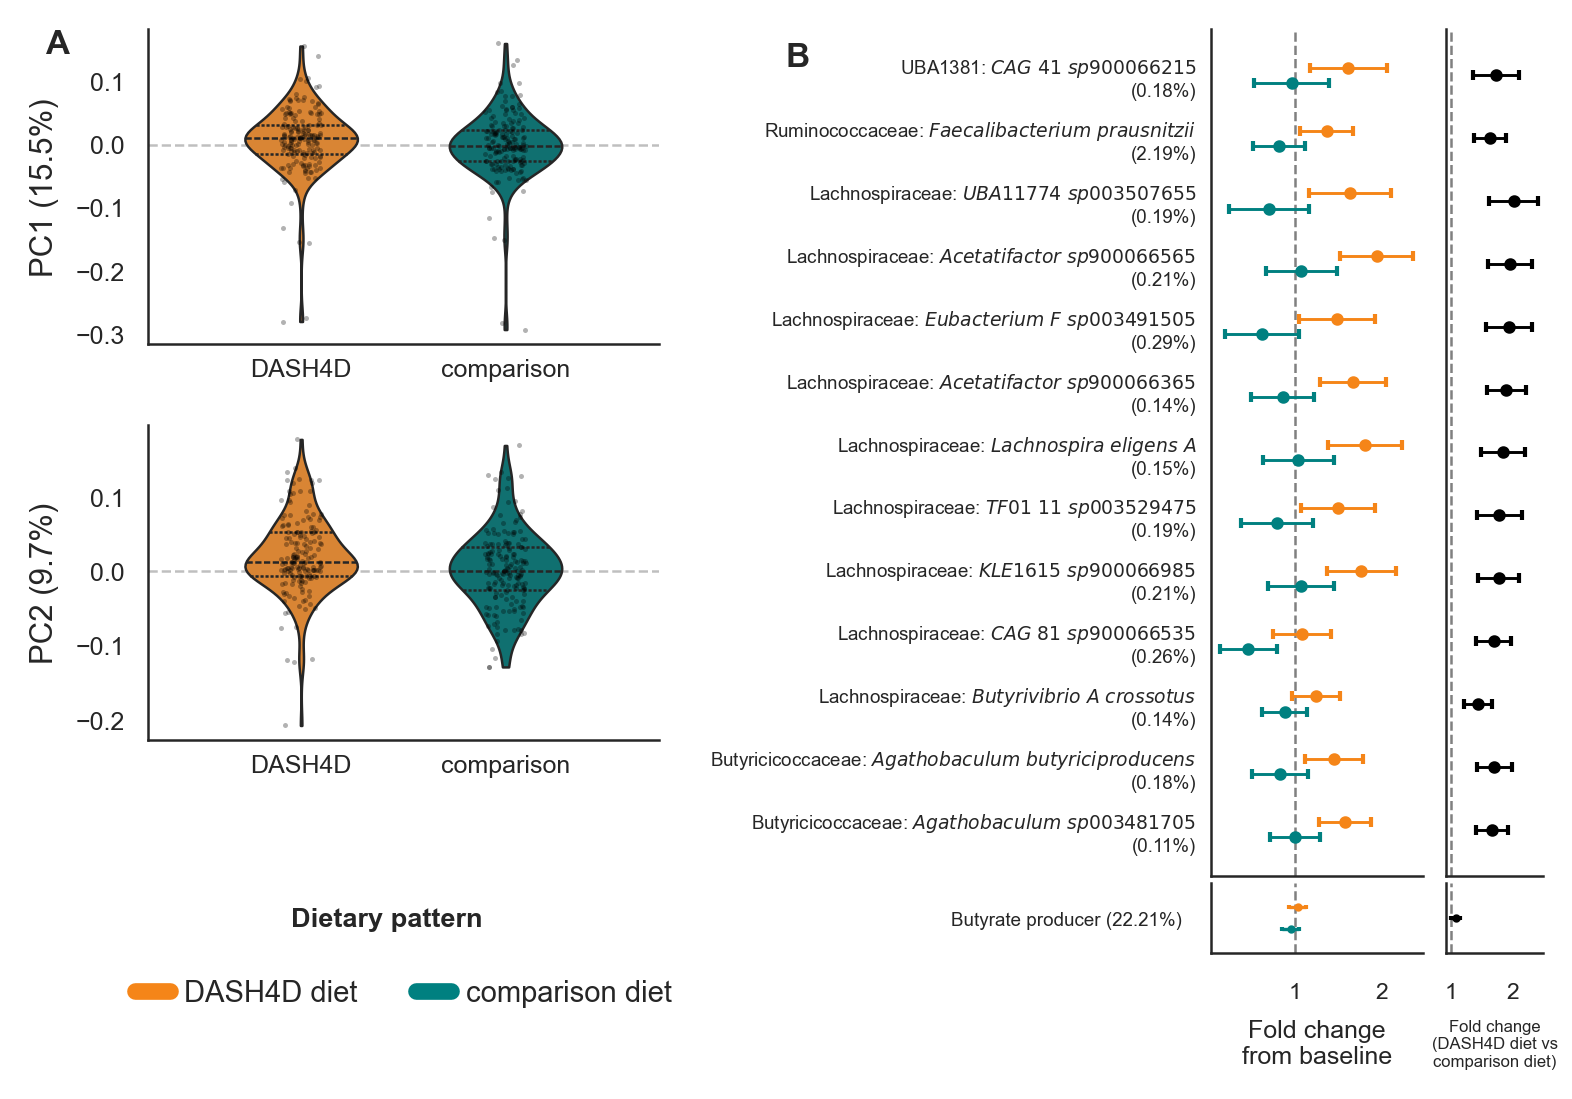

In [24]:
## set up figure and gridspec
fig1 = plt.figure(figsize=(6, 4), dpi=300)
sns.set_style("white")
fig1_gs = fig1.add_gridspec(1, 2, width_ratios=[6, 3], wspace=0.8)


# Panel A: PC1 and PC2 change profiles across the four diets
# Panel A: PC1 and PC2 across dietary patterns
# Pool low/high sodium within DASH4D and Comparison diets

PCA_changefrombaseline_width = PCA_changefrombaseline_width.copy()

PCA_changefrombaseline_width['diet_pattern'] = \
    PCA_changefrombaseline_width['diet'].map({
        'DL': 'DASH4D diet',
        'DH': 'DASH4D diet',
        'CL': 'Comparison diet',
        'CH': 'Comparison diet'
    })

diet_pattern_order = ['DASH4D diet', 'Comparison diet']

# Vertical layout: PC1, PC2, legend
fig1A_grid = fig1_gs[0].subgridspec(
    3, 2,
    width_ratios=[1, 0.30],       # blank space on right
    height_ratios=[1, 1, 0.42],
    hspace=0.32,
    wspace=0
)


fig1A_pc1 = fig1.add_subplot(fig1A_grid[0, 0])
fig1A_pc2 = fig1.add_subplot(fig1A_grid[1, 0])
fig1A_legend = fig1.add_subplot(fig1A_grid[2, 0])


# PC1
sns.violinplot(
    data=PCA_changefrombaseline_width,
    x='diet_pattern',
    y='PC1',
    order=diet_pattern_order,
    palette=color_dict,
    inner='quart',
    cut=0,
    width=0.55,          # narrower violin
    linewidth=0.6,
    ax=fig1A_pc1
)

sns.stripplot(
    data=PCA_changefrombaseline_width,
    x='diet_pattern',
    y='PC1',
    order=diet_pattern_order,
    color='black',
    size=1.2,
    alpha=0.30,
    jitter=0.10,         # slightly tighter jitter
    ax=fig1A_pc1
)


# PC2
sns.violinplot(
    data=PCA_changefrombaseline_width,
    x='diet_pattern',
    y='PC2',
    order=diet_pattern_order,
    palette=color_dict,
    inner='quart',
    cut=0,
    width=0.55,          # narrower violin
    linewidth=0.6,
    ax=fig1A_pc2
)

sns.stripplot(
    data=PCA_changefrombaseline_width,
    x='diet_pattern',
    y='PC2',
    order=diet_pattern_order,
    color='black',
    size=1.2,
    alpha=0.30,
    jitter=0.10,
    ax=fig1A_pc2
)


# Formatting
fig1A_pc1.set_ylabel('PC1 (15.5%)', fontsize=7.5)
fig1A_pc2.set_ylabel('PC2 (9.7%)', fontsize=7.5)


fig1A_pc1.set_xlabel('')
fig1A_pc2.set_xlabel('')

for ax in [fig1A_pc1, fig1A_pc2]:
    ax.axhline(
        0,
        color='grey',
        lw=0.6,
        ls='--',
        alpha=0.5,
        zorder=0
    )

    ax.tick_params(
        axis='both',
        labelsize=6,
        length=2
    )

    sns.despine(ax=ax)

    for spine in ax.spines.values():
        spine.set_linewidth(0.6)

# Since the legend identifies the groups, remove x-axis group labels
fig1A_pc1.set_xticklabels(
    ['DASH4D', 'comparison'],
    fontsize=6
)

fig1A_pc2.set_xticklabels(
    ['DASH4D', 'comparison'],
    fontsize=6
)

fig1A_pc1.tick_params(axis='x', length=0)
fig1A_pc2.tick_params(axis='x', length=0)

for ax in [fig1A_pc1, fig1A_pc2]:
    ax.set_xlim(-0.75, 1.75)


# Legend
fig1A_legend.axis('off')

legend_elements = [
    Line2D(
        [0], [0],
        color=color_dict['DASH4D diet'],
        lw=4,
        label='DASH4D diet'
    ),
    Line2D(
        [0], [0],
        color=color_dict['Comparison diet'],
        lw=4,
        label='comparison diet'
    )
]

fig1A_legend.text(
    0.28, 0.35,
    'Dietary pattern',
    transform=fig1A_legend.transAxes,
    fontsize=6.5,
    fontweight='bold',
    va='top'
)

fig1A_legend.legend(
    handles=legend_elements,
    loc='lower center',
    frameon=False,
    ncol=2,
    handlelength=1.2,
    handletextpad=0.5,
    labelspacing=0.35,
    bbox_to_anchor=(0.5, -0.5),   # move legend downward
    borderaxespad=0,
    prop={'size': 7}
)

# Panel label
fig1A_pc1.text(
    -0.20, 1, 'A',
    transform=fig1A_pc1.transAxes,
    fontsize=8,
    fontweight='bold',
    va='top'
)

# Panel B and C: change from baseline, differnece in difference
fig1BC_DA_grid = fig1_gs[1].subgridspec(2, 2,
                                        width_ratios=[2.2, 1],
                                        height_ratios=[12, 1],
                                        hspace=0.015, wspace=0.15)

fig1B_frombaseline_species = fig1.add_subplot(fig1BC_DA_grid[0,0])
fig1B_frombaseline_buty = fig1.add_subplot(fig1BC_DA_grid[1,0],
                                           sharex=fig1B_frombaseline_species)

fig1C_DID_species = fig1.add_subplot(fig1BC_DA_grid[0,1],
                                     sharey=fig1B_frombaseline_species)
fig1C_DID_buty = fig1.add_subplot(fig1BC_DA_grid[1,1],
                                  sharex=fig1C_DID_species,
                                  sharey=fig1B_frombaseline_buty)

fig1B_frombaseline_species.errorbar(FC_DA_species_vis_data['log2fc_dash_baseline'],
                                    FC_DA_species_vis_data['vis_order'] + 0.12,
                                    xerr=FC_DA_species_vis_data['err_dash_baseline'],
                                    fmt='o',
                                    color=color_dict['DASH4D diet'],
                                    capsize=1.2,
                                    markersize=2,
                                    elinewidth=0.7,
                                    zorder=3
                                   )
fig1B_frombaseline_species.errorbar(FC_DA_species_vis_data['log2fc_comp_baseline'],
                                    FC_DA_species_vis_data['vis_order'] - 0.12,
                                    xerr=FC_DA_species_vis_data['err_comp_baseline'],
                                    fmt='o',
                                    color=color_dict['Comparison diet'],
                                    capsize=1.2,
                                    markersize=2,
                                    elinewidth=0.7,
                                    zorder=3
                                   )

fig1B_frombaseline_buty.errorbar(FC_DA_butyrate_vis_data['log2fc_dash_baseline'],
                                 0.08,
                                 xerr=FC_DA_butyrate_vis_data['err_dash_baseline'],
                                 fmt='o',
                                 color=color_dict['DASH4D diet'],
                                 capsize=0.5,
                                 markersize=1,
                                 elinewidth=0.8,
                                 zorder=3
                                )

fig1B_frombaseline_buty.errorbar(FC_DA_butyrate_vis_data['log2fc_comp_baseline'],
                                 -0.08,
                                 xerr=FC_DA_butyrate_vis_data['err_comp_baseline'],
                                 fmt='o',
                                 color=color_dict['Comparison diet'],
                                 capsize=0.5,
                                 markersize=1,
                                 elinewidth=0.8,
                                 zorder=3
                                )
fig1B_frombaseline_buty.set_xticks([0,1])
fig1B_frombaseline_buty.set_xticklabels(["1", "2"])


fig1C_DID_species.errorbar(FC_DA_species_vis_data['log2fc_dash_comp'],
                           FC_DA_species_vis_data['vis_order'],
                           xerr=FC_DA_species_vis_data['err_dash_comp'],
                           fmt='o',
                           color='black',
                           capsize=1.2,
                           markersize=2,
                           elinewidth=0.7,
                           zorder=3
                          )

fig1C_DID_buty.errorbar(FC_DA_butyrate_vis_data['log2fc_dash_comp'],
                        0,
                        xerr=FC_DA_butyrate_vis_data['err_dash_comp'],
                        fmt='o',
                        color='black',
                        capsize=0.5,
                        markersize=1,
                        elinewidth=0.8,
                        zorder=3
                       )

fig1C_DID_buty.set_xticks([0,1])
fig1C_DID_buty.set_xticklabels(["1", "2"])


fig1B_frombaseline_buty.set_ylim(-0.25, 0.25)
fig1C_DID_buty.set_ylim(-0.25, 0.25)

# set up taxonomy labels
fig1B_frombaseline_species.set_yticks(FC_DA_species_vis_data['vis_order'])
fig1B_frombaseline_species.set_yticklabels(FC_DA_species_vis_data['vis_label_wrap'],
                                           ha='right',
                                           fontsize=4.5,
                                           )
fig1B_frombaseline_buty.set_yticks([0])
fig1B_frombaseline_buty.set_yticklabels(FC_DA_butyrate_vis_data['vis_label_wrap'],
                                        ha='right',
                                        fontsize=4.5)

fig1B_frombaseline_species.tick_params(axis='y', pad=0)

# Panel Labels
fig1B_frombaseline_species.text(-2, 0.985, 'B',
                                transform=fig1B_frombaseline_species.transAxes,
                                fontsize=8,
                                fontweight='bold',
                                va='top')

# fig1C_DID_species.text(-0.1, 1.1, 'C',
#                        transform=fig1C_DID_species.transAxes,
#                        fontsize=8,
#                        fontweight='bold',
#                        va='top')


for ax in [fig1B_frombaseline_species, fig1B_frombaseline_buty,
           fig1C_DID_species, fig1C_DID_buty]:
    ax.axvline(0, color='grey', lw=0.6, ls='--', zorder=2)
    ax.tick_params(axis='x', labelsize=5.5)
    sns.despine(ax=ax)
    for s in ax.spines.values(): s.set_linewidth(0.6)

plt.setp(fig1B_frombaseline_species.get_xticklabels(), visible=False)
plt.setp(fig1C_DID_species.get_xticklabels(), visible=False)
plt.setp(fig1C_DID_species.get_yticklabels(), visible=False)
plt.setp(fig1C_DID_buty.get_yticklabels(), visible=False)


fig1B_frombaseline_buty.set_xlabel("Fold change\nfrom baseline", fontsize=6)
fig1C_DID_buty.set_xlabel("Fold change\n(DASH4D diet vs\ncomparison diet)", fontsize=4)

plt.savefig(f"{PAPER_FIG}/fig1.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{PAPER_FIG}/fig1.pdf", dpi=300, bbox_inches='tight')

### Figure 2

#### Prepare gene effect and contribution data

In [25]:
sig_shape_dict = {
    'p < 0.05': 'o',
    'BH-adjusted p < 0.05': 's',
    'holm-adjusted p < 0.05': 'D'
}

In [26]:
# Function to prepare data for one gene

def prepare_gene_plot_data(
    gene_prefix,
    gene_label
):
    """
    gene_prefix:
        'but', 'EtfA', or 'EtfB'

    gene_label:
        'But', 'EtfA', or 'EtfB'
    """

    # Read data

    byspecies_df = pd.read_csv(
        f"{INTERMEDIATE_MICRO}/{gene_prefix}_gene_DASH_effect.tsv",
        sep='\t'
    )

    distr_long = pd.read_csv(
        f"{INTERMEDIATE_MICRO}/{gene_prefix}_gene_contri_data.tsv",
        sep='\t'
    )


    # Overall gene abundance

    total = (
        byspecies_df
        .loc[byspecies_df['gene'] == 'total']
        .copy()
    )

    total['gene'] = f'{gene_label} gene in total'


    # Keep complete strain-specific results

    byspecies_complete = (
        byspecies_df
        .loc[byspecies_df['gene'] != 'total']
        .dropna()
        .copy()
    )


    # Select nominally significant strain-specific genes
    
    byspecies_complete_sig = (
        byspecies_complete
        .loc[byspecies_complete['pval'] < 0.05]
        .copy()
    )
    
    
    # Order strains by median contribution
    
    gene_order_sig = (
        distr_long
        .loc[
            distr_long['taxon'].isin(
                byspecies_complete_sig['gene']
            )
        ]
        .groupby('taxon')['p_contri']
        .median()
        .rename('p_contri')
    )
    
    
    byspecies_complete_order_sig = pd.merge(
        byspecies_complete_sig,
        gene_order_sig,
        left_on='gene',
        right_index=True,
        how='inner'
    )
    
    
    byspecies_vis_data_sig = (
        byspecies_complete_order_sig
        .sort_values(by='p_contri')
        .reset_index(drop=True)
    )
    
    
    byspecies_vis_data_sig['vis_order'] = (
        np.arange(len(byspecies_vis_data_sig)) + 1
    )
    
    
    # Add visualization order to contribution data
    
    distr_long_vis_order_sig = pd.merge(
        distr_long,
        byspecies_vis_data_sig[
            ['gene', 'vis_order']
        ],
        left_on='taxon',
        right_on='gene',
        how='inner'
    )
    
    
    # Assign significance category
    
    byspecies_vis_data_sig['significance_group'] = 'p < 0.05'
    
    byspecies_vis_data_sig.loc[
        byspecies_vis_data_sig['p_BH'] < 0.05,
        'significance_group'
    ] = 'BH-adjusted p < 0.05'
    
    byspecies_vis_data_sig.loc[
        byspecies_vis_data_sig['p_holm'] < 0.05,
        'significance_group'
    ] = 'holm-adjusted p < 0.05'


    # Overall gene row

    total_sig = total.copy()
    total_sig['vis_order'] = -2


    # Dataset used for y-axis labels

    byspecies_vis_data_sig_withtotal = (
        pd.concat(
            [
                byspecies_vis_data_sig,
                total_sig
            ],
            ignore_index=True
        )
        .sort_values(by='vis_order')
        .reset_index(drop=True)
    )


    # Separate significance groups

    byspecies_vis_holm_sig = (
        byspecies_vis_data_sig.loc[
            byspecies_vis_data_sig['significance_group']
            == 'holm-adjusted p < 0.05'
        ]
        .copy()
    )

    byspecies_vis_bh_sig = (
        byspecies_vis_data_sig.loc[
            byspecies_vis_data_sig['significance_group']
            == 'BH-adjusted p < 0.05'
        ]
        .copy()
    )

    byspecies_vis_pval_sig = (
        byspecies_vis_data_sig.loc[
            byspecies_vis_data_sig['significance_group']
            == 'p < 0.05'
        ]
        .copy()
    )


    return {
        'prefix': gene_prefix,
        'label': gene_label,

        'dist': distr_long_vis_order_sig,

        'all_sig': byspecies_vis_data_sig,

        'holm': byspecies_vis_holm_sig,
        'bh': byspecies_vis_bh_sig,
        'pval': byspecies_vis_pval_sig,

        'total': total_sig,

        'labels': byspecies_vis_data_sig_withtotal,

        'n_gene': len(byspecies_vis_data_sig)
    }

In [27]:
gene_info = [
    ('but', 'But'),
    ('EtfA', 'EtfA'),
    ('EtfB', 'EtfB')
]


gene_plot_data = [
    prepare_gene_plot_data(
        gene_prefix=gene_prefix,
        gene_label=gene_label
    )
    for gene_prefix, gene_label in gene_info
]

In [28]:
# Function to plot one gene panel

def plot_one_gene_panel(
    fig,
    gs_cell,
    gene_data,
    contribution_xlim=(0, 0.5),
    did_xlim=(0, 1.5),
    show_xlabel=True
):

    # Two columns:
    # left  = contribution
    # right = DASH4D vs comparison

    panel_gs = gs_cell.subgridspec(
        1,
        2,
        width_ratios=[1,1],
        wspace=4
    )

    ax_dist = fig.add_subplot(
        panel_gs[0, 0]
    )

    ax_did = fig.add_subplot(
        panel_gs[0, 1],
        sharey=ax_dist
    )


    n_gene = gene_data['n_gene']

    # Gene positions:
    # 0, 1, 2, ..., n_gene - 1
    gene_positions = list(range(n_gene))

    # Overall gene effect
    total_position = -2


    # LEFT: contribution distribution

    if len(gene_data['dist']) > 0:

        sns.boxplot(
            data=gene_data['dist'],
            y='vis_order',
            x='p_contri',
            orient='h',
            fill=False,
            color='black',
            ax=ax_dist,
            legend=False,
            width=0.5,
            linewidth=0.5,
            fliersize=0.1
        )


    ax_dist.tick_params(
        axis='y',
        right=True,
        labelright=False,
        labelleft=False,
        length=0
    )

    ax_dist.set_ylabel("")


    # Contribution x-axis

    ax_dist.set_xlim(contribution_xlim)

    
    ax_dist.set_xticks([
        0, 0.2, 0.4
    ])
    
    ax_dist.set_xticklabels(
        ['0', '20', '40'],
        fontsize=6
    )

    if show_xlabel:
        ax_dist.set_xlabel(
            "Contribution\nto gene(%)",
            fontsize=6.5
        )
    else:
        ax_dist.set_xlabel("")

    ax_dist.tick_params(
        axis='x',
        labelsize=5,
        pad=0
    )

    ax_dist.invert_xaxis()

    # Contribution plot styling
    ax_dist.spines['left'].set_visible(False)
    ax_dist.spines['top'].set_visible(False)
    ax_dist.spines['right'].set_visible(False)   # because x=0 baseline is drawn manually
    
    ax_dist.spines['bottom'].set_visible(True)
    ax_dist.spines['bottom'].set_linewidth(0.5)

    # Draw explicit 0% contribution baseline
    ax_dist.axvline(
        x=0,
        color='black',
        linewidth=0.5,
        zorder=1
    )
    


    # RIGHT: intervention effect

    significance_data = [
        (
            gene_data['pval'],
            'p < 0.05'
        ),
        (
            gene_data['bh'],
            'BH-adjusted p < 0.05'
        ),
        (
            gene_data['holm'],
            'holm-adjusted p < 0.05'
        )
    ]


    for df, sig_group in significance_data:

        if len(df) == 0:
            continue

        ax_did.errorbar(
            df['DASHvComp'],
            df['vis_order'] - 1,
            xerr=df['DASHvComp_err'],
            fmt=sig_shape_dict[sig_group],
            color='black',
            markersize=1.5,
            elinewidth=0.5,
            zorder=3
        )


    # Overall gene effect

    if len(gene_data['total']) > 0:

        estimate = gene_data['total']['DASHvComp'].iloc[0]
        err = gene_data['total']['DASHvComp_err'].iloc[0]

        ci_low = estimate - err
        ci_high = estimate + err

        diamond_height = 0.20

        diamond = Polygon(
        [
            [ci_low, total_position],                    # left = lower CI
            [estimate, total_position + diamond_height], # top = estimate
            [ci_high, total_position],                   # right = upper CI
            [estimate, total_position - diamond_height]  # bottom = estimate
        ],
        closed=True,
        facecolor='firebrick',
        edgecolor='firebrick',
        linewidth=0.6,
        zorder=5
        )

        ax_did.add_patch(diamond)


    # Null effect

    ax_did.axvline(
        x=1,
        color='gray',
        linestyle='--',
        linewidth=0.5,
        alpha=0.7,
        zorder=1
    )


    # Separate overall effect from strain-level effects

    ax_did.axhline(
        y=-1,
        color='lightgray',
        linewidth=0.4,
        zorder=1
    )


    # Dynamic y-axis

    ytick_positions = (
        [total_position]
        + gene_positions
    )

    ytick_labels = (
        gene_data['labels']['gene']
        .tolist()
    )


    ax_did.set_yticks(
        ytick_positions
    )

    ax_did.set_yticklabels(
        ytick_labels,
        fontsize=4.5
    )


    # Dynamic y-limits based on number of genes
    y_bottom = -2.8

    if n_gene > 0:
        y_top = n_gene - 0.5
    else:
        y_top = 0.5

    ax_did.set_ylim(
        y_bottom,
        y_top
    )


    ax_did.set_ylabel("")

    ax_did.yaxis.tick_left()
    ax_did.yaxis.set_label_position("left")

    ax_did.tick_params(
        axis='y',
        length=1.2,
        pad=0.5
    )


    # DID x-axis

    ax_did.set_xlim(did_xlim)

    ax_did.set_xticks(
        [0.5, 1, 1.5]
    )

    ax_did.set_xticklabels(
        ['0.5', '1.0', '1.5'],
        fontsize=6
    )

    if show_xlabel:
        ax_did.set_xlabel(
            "Fold difference\n(DASH4D vs comparison diet)",
            fontsize=6.5
        )
    else:
        ax_did.set_xlabel("")

    ax_did.tick_params(
        axis='x',
        pad=0
    )


    # Highlight overall-gene label

    for tick_pos, tick_label in zip(
        ax_did.get_yticks(),
        ax_did.get_yticklabels()
    ):

        if tick_pos == total_position:

            tick_label.set_fontsize(6)
            tick_label.set_fontweight('bold')
            tick_label.set_fontweight('bold')
            tick_label.set_color('firebrick')

        else:

            tick_label.set_fontsize(6)
            tick_label.set_fontweight('normal')
            tick_label.set_fontstyle('italic')
            tick_label.set_color('black')


    # Gene panel title

    ax_dist.set_title("")

    ax_dist.text(
        0.0,
        1.08,
        gene_data['label'],
        transform=ax_dist.transAxes,
        fontsize=6.5,
        fontweight='bold',
        ha='left',
        va='bottom',
        clip_on=False
    )


    # Clean axes

    # LEFT contribution plot:
    # remove left/top/right borders
    # retain bottom x-axis
    sns.despine(
        ax=ax_dist,
        left=True,
        right=True,
        top=True,
        bottom=False
    )
    
    ax_dist.spines['bottom'].set_linewidth(0.5)
    
    
    # RIGHT forest plot:
    # keep left + bottom axes
    sns.despine(
        ax=ax_did,
        left=False,
        right=True,
        top=True,
        bottom=False
    )
    
    ax_did.spines['left'].set_linewidth(0.5)
    ax_did.spines['bottom'].set_linewidth(0.5)


    return ax_dist, ax_did

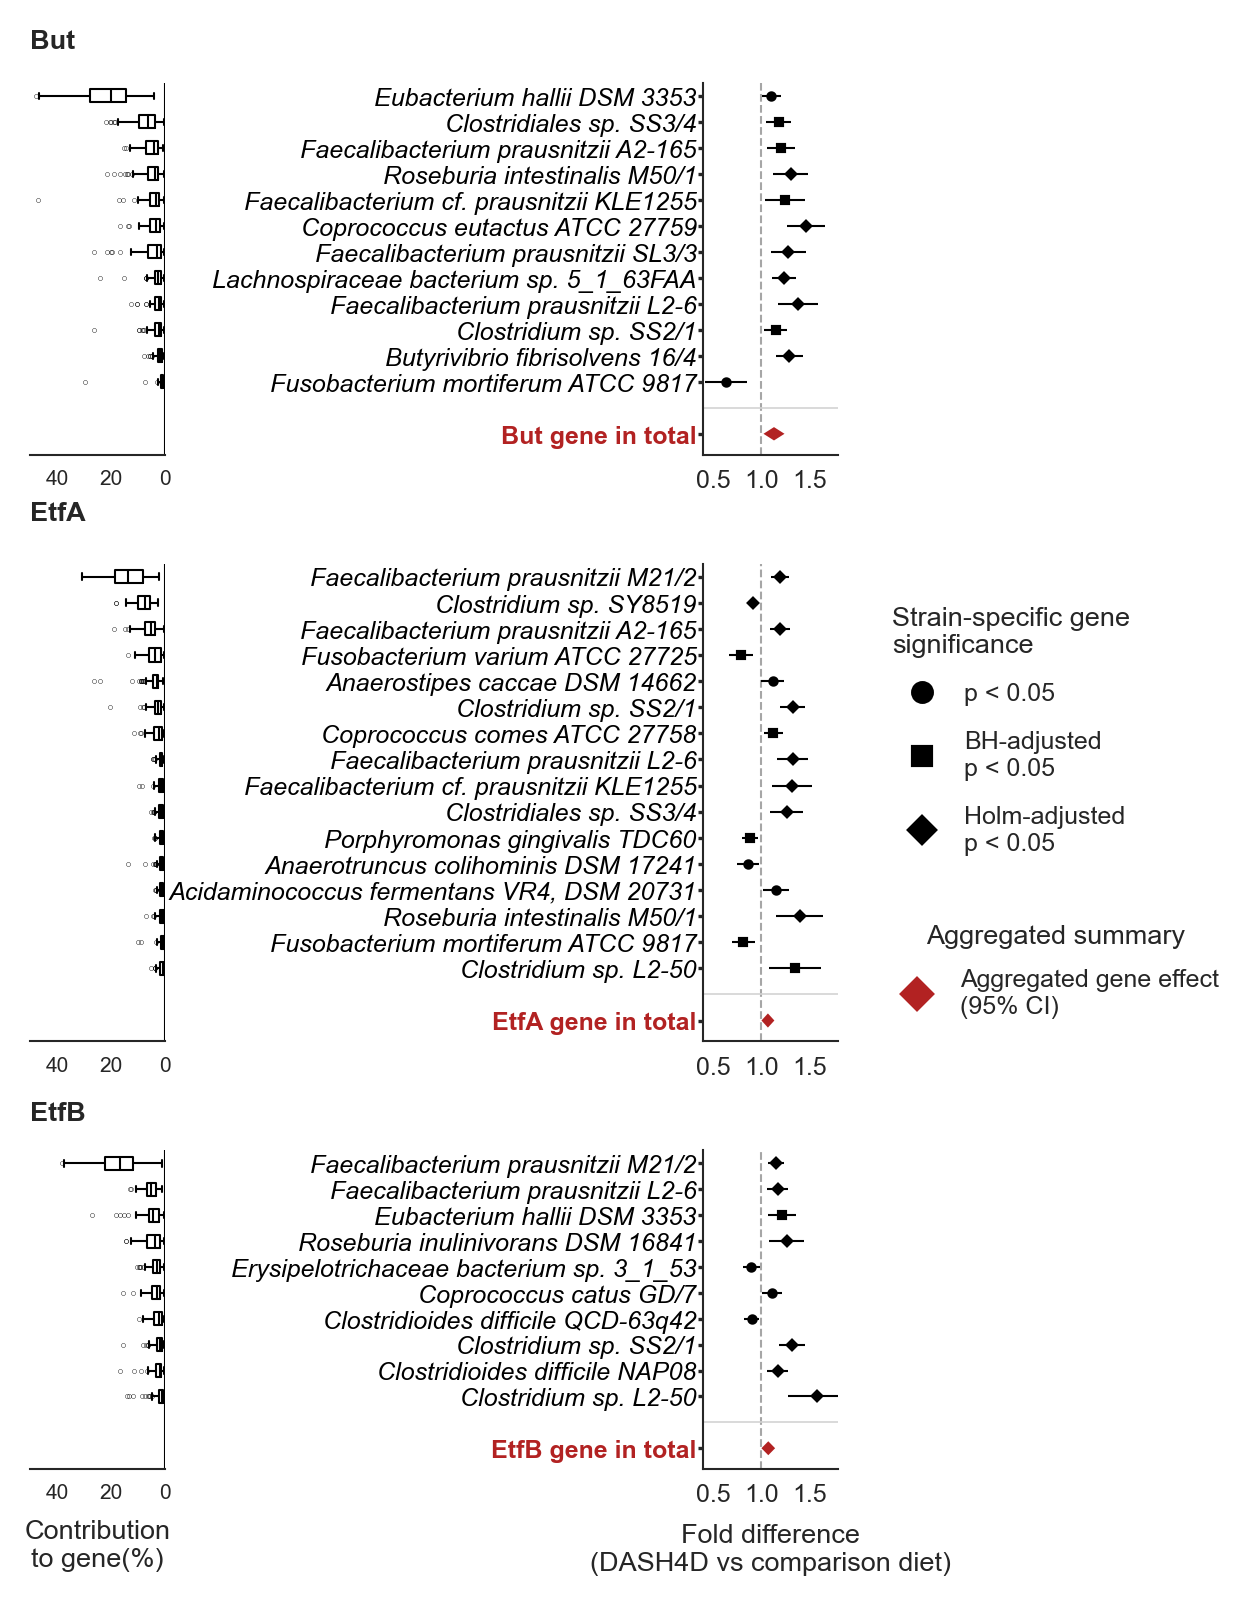

In [29]:
# Figure

but_gene_sig_fig = plt.figure(
    figsize=(4, 6),
    dpi=300
)

sns.set_style("white")


# Dynamic panel heights

panel_heights = [
    max(x['n_gene'] + 2, 5)
    for x in gene_plot_data
]


# Outer layout
#
# left column  = But / EtfA / EtfB plots
# right column = shared significance legend

but_gene_sig_fig_gs = but_gene_sig_fig.add_gridspec(
    3,
    2,
    height_ratios=panel_heights,
    width_ratios=[5.2, 0.5],
    hspace=0.28,
    wspace=0.1
)

# Plot all three genes

all_axes = []

for i, gene_data in enumerate(gene_plot_data):

    show_xlabel = (
        i == len(gene_plot_data) - 1
    )

    axes = plot_one_gene_panel(
        fig=but_gene_sig_fig,
        gs_cell=but_gene_sig_fig_gs[i, 0],
        gene_data=gene_data,
        contribution_xlim=(0, 0.50),
        did_xlim=(0.4, 1.8),
        show_xlabel=show_xlabel
    )

    all_axes.append(axes)

# Shared significance legend on right

but_gene_sig_legend = but_gene_sig_fig.add_subplot(
    but_gene_sig_fig_gs[:, 1]
)

but_gene_sig_legend.axis('off')

# Legend 1: strain-specific gene significance

strain_legend_elements = [

    Line2D(
        [0], [0],
        marker=sig_shape_dict['p < 0.05'],
        linestyle='None',
        markerfacecolor='black',
        markeredgecolor='black',
        markersize=4.5,
        label='p < 0.05'
    ),

    Line2D(
        [0], [0],
        marker=sig_shape_dict['BH-adjusted p < 0.05'],
        linestyle='None',
        markerfacecolor='black',
        markeredgecolor='black',
        markersize=4.5,
        label='BH-adjusted\np < 0.05'
    ),

    Line2D(
        [0], [0],
        marker=sig_shape_dict['holm-adjusted p < 0.05'],
        linestyle='None',
        markerfacecolor='black',
        markeredgecolor='black',
        markersize=4.5,
        label='Holm-adjusted\np < 0.05'
    )
]


strain_legend = but_gene_sig_legend.legend(
    handles=strain_legend_elements,
    title='Strain-specific gene\nsignificance',
    loc='upper left',
    bbox_to_anchor=(0.0, 0.63),
    frameon=False,
    ncol=1,
    fontsize=6,
    title_fontsize=6.5,
    handletextpad=0.7,
    labelspacing=1.0,
    borderaxespad=0
)

# Important: keep this legend when adding the second one
but_gene_sig_legend.add_artist(strain_legend)

but_gene_sig_legend.legend(
    handles=strain_legend_elements,
    title='Significance',
    loc='center left',
    frameon=False,
    ncol=1,
    fontsize=5,
    title_fontsize=5.5,
    handletextpad=0.7,
    labelspacing=1.2,
    borderaxespad=0
)

# Legend 2: aggregated summary

summary_legend_elements = [

    Line2D(
        [0], [0],
        marker='D',
        linestyle='None',
        markerfacecolor='firebrick',
        markeredgecolor='firebrick',
        markersize=5,
        label='Aggregated gene effect\n(95% CI)'
    )
]


summary_legend = but_gene_sig_legend.legend(
    handles=summary_legend_elements,
    title='Aggregated summary',
    loc='upper left',
    bbox_to_anchor=(0.0, 0.40),
    frameon=False,
    ncol=1,
    fontsize=6,
    title_fontsize=6.5,
    handletextpad=0.7,
    labelspacing=0.8,
    borderaxespad=0
)

plt.savefig(
    f"{PAPER_FIG}/fig2.png",
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.02
)

plt.savefig(
    f"{PAPER_FIG}/fig2.pdf",
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.02
)

### Figure 3

In [30]:
fecal_SCFA_DASH = pd.read_csv(f"{INTERMEDIATE_SCFA}/fecal_scfa_results_DASH.tsv", sep='\t')
plasma_SCFA_DASH = pd.read_csv(f"{INTERMEDIATE_SCFA}/plasma_scfa_results_DASH.tsv", sep='\t')
fecal_SCFA_sodium = pd.read_csv(f"{INTERMEDIATE_SCFA}/fecal_scfa_results_sodium.tsv", sep='\t')
plasma_SCFA_sodium = pd.read_csv(f"{INTERMEDIATE_SCFA}/plasma_scfa_results_sodium.tsv", sep='\t')

In [31]:
fecal_SCFA_DASH = fecal_SCFA_DASH[fecal_SCFA_DASH['scfa'] != 'succinate'].copy()
plasma_SCFA_DASH = plasma_SCFA_DASH[plasma_SCFA_DASH['scfa'] != 'succinate'].copy()
plasma_SCFA_sodium = plasma_SCFA_sodium[plasma_SCFA_sodium['scfa'] != 'succinate'].copy()
fecal_SCFA_sodium = fecal_SCFA_sodium[fecal_SCFA_sodium['scfa'] != 'succinate'].copy()

In [32]:
fecal_SCFA_DASH['logfc'] = fecal_SCFA_DASH['Est.']
fecal_SCFA_DASH['err'] = fecal_SCFA_DASH['Est.'] - fecal_SCFA_DASH['X2.5.']
fecal_SCFA_DASH['vis_order'] = fecal_SCFA_DASH.index[::-1]
fecal_SCFA_DASH_df = fecal_SCFA_DASH[['logfc', 'err', 'vis_order', 'scfa']].copy()

plasma_SCFA_DASH['logfc'] = plasma_SCFA_DASH['Est.']
plasma_SCFA_DASH['err'] = plasma_SCFA_DASH['Est.'] - plasma_SCFA_DASH['X2.5.']
plasma_SCFA_DASH['vis_order'] = plasma_SCFA_DASH.index[::-1]
plasma_SCFA_DASH_df = plasma_SCFA_DASH[['logfc', 'err', 'vis_order', 'scfa']].copy()

fecal_SCFA_sodium['logfc'] = fecal_SCFA_sodium['Est.']
fecal_SCFA_sodium['err'] = fecal_SCFA_sodium['Est.'] - fecal_SCFA_sodium['X2.5.']
fecal_SCFA_sodium['vis_order'] = fecal_SCFA_sodium.index[::-1]
fecal_SCFA_sodium_df = fecal_SCFA_sodium[['logfc', 'err', 'vis_order', 'scfa']].copy()

plasma_SCFA_sodium['logfc'] = plasma_SCFA_sodium['Est.']
plasma_SCFA_sodium['err'] = plasma_SCFA_sodium['Est.'] - plasma_SCFA_sodium['X2.5.']
plasma_SCFA_sodium['vis_order'] = plasma_SCFA_sodium.index[::-1]
plasma_SCFA_sodium_df = plasma_SCFA_sodium[['logfc', 'err', 'vis_order', 'scfa']].copy()

In [33]:
fecal_SCFA_DASH_df['scfa'] = fecal_SCFA_DASH_df['scfa'].str.capitalize()
plasma_SCFA_DASH_df['scfa'] = plasma_SCFA_DASH_df['scfa'].str.capitalize()
fecal_SCFA_sodium_df['scfa'] = fecal_SCFA_sodium_df['scfa'].str.capitalize()
plasma_SCFA_sodium_df['scfa'] = plasma_SCFA_sodium_df['scfa'].str.capitalize()

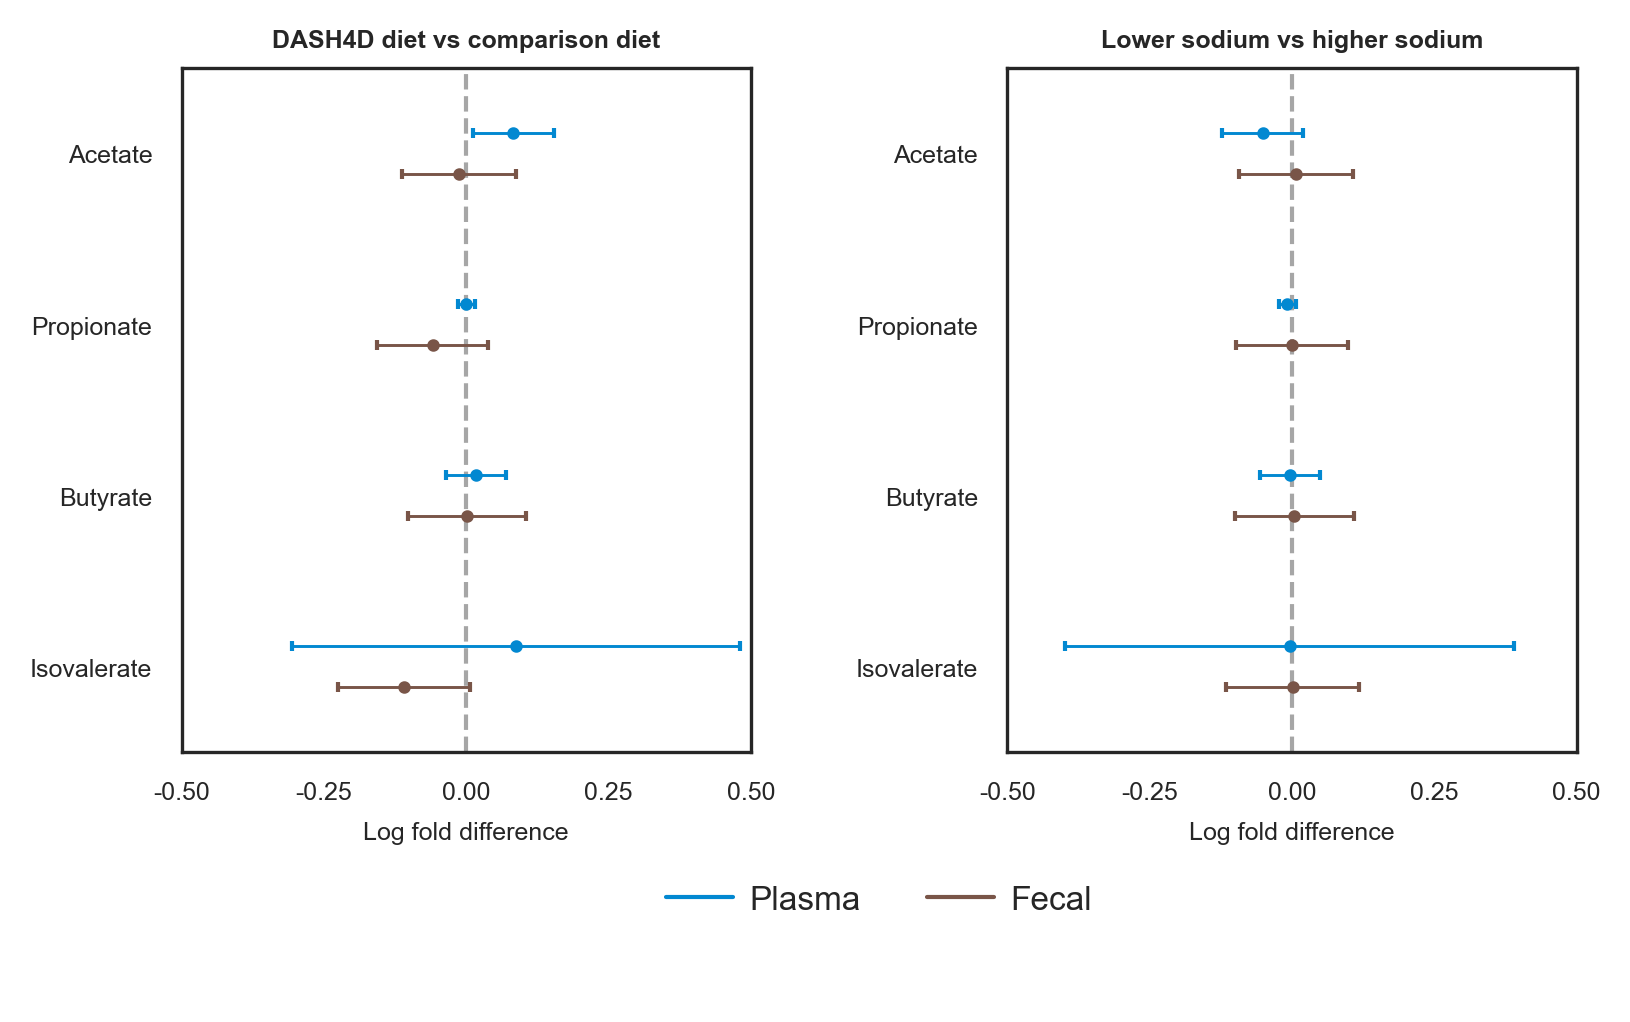

In [34]:
## set up figure and gridspec
fig2_bycomparison = plt.figure(figsize=(6, 4), dpi=300)
sns.set_style("white")
fig2_bycomparison_gs = fig2_bycomparison.add_gridspec(2, 2, height_ratios=[5, 1], width_ratios=[1,1], wspace=0.45, hspace=0.25)

fig2_DASH = fig2_bycomparison.add_subplot(fig2_bycomparison_gs[0, 0])

fig2_DASH.errorbar(plasma_SCFA_DASH_df['logfc'],
                     plasma_SCFA_DASH_df['vis_order'] + 0.12,
                     xerr=plasma_SCFA_DASH_df['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

fig2_DASH.errorbar(fecal_SCFA_DASH_df['logfc'],
                     fecal_SCFA_DASH_df['vis_order'] - 0.12,
                     xerr=fecal_SCFA_DASH_df['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#795548',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

fig2_DASH.set_ylim(plasma_SCFA_DASH_df['vis_order'].iloc[-1] - 0.5, plasma_SCFA_DASH_df['vis_order'].iloc[0] + 0.5)
fig2_DASH.set_xlim(-0.5, 0.5)
fig2_DASH.set_yticks(plasma_SCFA_DASH_df['vis_order'])
fig2_DASH.set_yticklabels(plasma_SCFA_DASH_df['scfa'], fontsize=6)
fig2_DASH.set_title("DASH4D diet vs comparison diet", fontsize=6, fontweight='bold', pad=5)
fig2_DASH.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
fig2_DASH.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
fig2_DASH.set_xticklabels(["-0.50","-0.25", "0.00", "0.25", "0.50"], fontsize=6)
fig2_DASH.set_xlabel("Log fold difference", fontsize=6)

fig2_sodium = fig2_bycomparison.add_subplot(fig2_bycomparison_gs[0, 1])

fig2_sodium.errorbar(plasma_SCFA_sodium_df['logfc'],
                     plasma_SCFA_sodium_df['vis_order'] + 0.12,
                     xerr=plasma_SCFA_sodium_df['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

fig2_sodium.errorbar(fecal_SCFA_sodium_df['logfc'],
                     fecal_SCFA_sodium_df['vis_order'] - 0.12,
                     xerr=fecal_SCFA_sodium_df['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#795548',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

fig2_sodium.set_ylim(fecal_SCFA_DASH_df['vis_order'].iloc[-1] - 0.5, fecal_SCFA_DASH_df['vis_order'].iloc[0] + 0.5)
fig2_sodium.set_xlim(-0.5, 0.5)
fig2_sodium.set_yticks(fecal_SCFA_DASH_df['vis_order'])
fig2_sodium.set_yticklabels(fecal_SCFA_DASH_df['scfa'], fontsize=6)
fig2_sodium.set_title("Lower sodium vs higher sodium", fontsize=6, fontweight='bold', pad=5)
fig2_sodium.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
fig2_sodium.set_xticks([-0.5, -0.25, 0, 0.25, 0.5])
fig2_sodium.set_xticklabels(["-0.50","-0.25", "0.00", "0.25", "0.50"], fontsize=6)
fig2_sodium.set_xlabel("Log fold difference", fontsize=6)


fig2_bycomparison_legend = fig2_bycomparison.add_subplot(fig2_bycomparison_gs[1,:])

fig2_bycomparison_legend.axis('off')
fig2_bycomparison_legend_elements = [Line2D([0], [0], color='#0288D1', lw=1, label='Plasma'),
									 Line2D([0], [0], color='#795548', lw=1, label='Fecal')]
fig2_bycomparison_legend.legend(handles=fig2_bycomparison_legend_elements,
                              loc='upper center',
                              frameon=False,
                              ncol=2,
                              handletextpad=0.5,
                              bbox_to_anchor=(0.5,1),
                              prop={'size': 8})

plt.savefig(f"{PAPER_FIG}/fig3.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{PAPER_FIG}/fig3.pdf", dpi=300, bbox_inches='tight')

## Supplementary figures

### Figure S3 — Within-individual versus between-individual distances

In [35]:
ind_covariates_jaccard_comp_df = pd.read_csv(f"{INTERMEDIATE_MICRO}/ind_covariates_jaccard_comp_df.tsv", sep='\t')
ind_covariates_bc_comp_df = pd.read_csv(f"{INTERMEDIATE_MICRO}/ind_covariates_bc_comp_df.tsv", sep='\t')
ind_covariates_aitchison_comp_df = pd.read_csv(f"{INTERMEDIATE_MICRO}/ind_covariates_aitchison_comp_df.tsv", sep='\t')

In [36]:
ind_covariates_jaccard_comp_df['group_vis'] = \
    ind_covariates_jaccard_comp_df['group'].case_when([
        (ind_covariates_jaccard_comp_df['group'] == "Within-individual","Within\nindividual"),
        (ind_covariates_jaccard_comp_df['group'] == "Within-diet","Within\ndiet"),
        (ind_covariates_jaccard_comp_df['group'] == "Within-visit","Within\nvisit"),
    ]
    )

ind_covariates_bc_comp_df['group_vis'] = \
    ind_covariates_bc_comp_df['group'].case_when([
        (ind_covariates_bc_comp_df['group'] == "Within-individual","Within\nindividual"),
        (ind_covariates_bc_comp_df['group'] == "Within-diet","Within\ndiet"),
        (ind_covariates_bc_comp_df['group'] == "Within-visit","Within\nvisit"),
    ]
    )

ind_covariates_aitchison_comp_df['group_vis'] = \
    ind_covariates_aitchison_comp_df['group'].case_when([
        (ind_covariates_aitchison_comp_df['group'] == "Within-individual","Within\nindividual"),
        (ind_covariates_aitchison_comp_df['group'] == "Within-diet","Within\ndiet"),
        (ind_covariates_aitchison_comp_df['group'] == "Within-visit","Within\nvisit"),
    ]
    )

In [37]:
ind_covariates_jaccard_comp_df['group_vis'] = pd.Categorical(ind_covariates_jaccard_comp_df['group_vis'],
                                                         categories=['Within\nindividual',
                                                                     'Within\ndiet',
                                                                     'Within\nvisit'],
                                                         ordered=True)

ind_covariates_bc_comp_df['group_vis'] = pd.Categorical(ind_covariates_bc_comp_df['group_vis'],
                                                         categories=['Within\nindividual',
                                                                     'Within\ndiet',
                                                                     'Within\nvisit'],
                                                         ordered=True)

ind_covariates_aitchison_comp_df['group_vis'] = pd.Categorical(ind_covariates_aitchison_comp_df['group_vis'],
                                                         categories=['Within\nindividual',
                                                                     'Within\ndiet',
                                                                     'Within\nvisit'],
                                                         ordered=True)


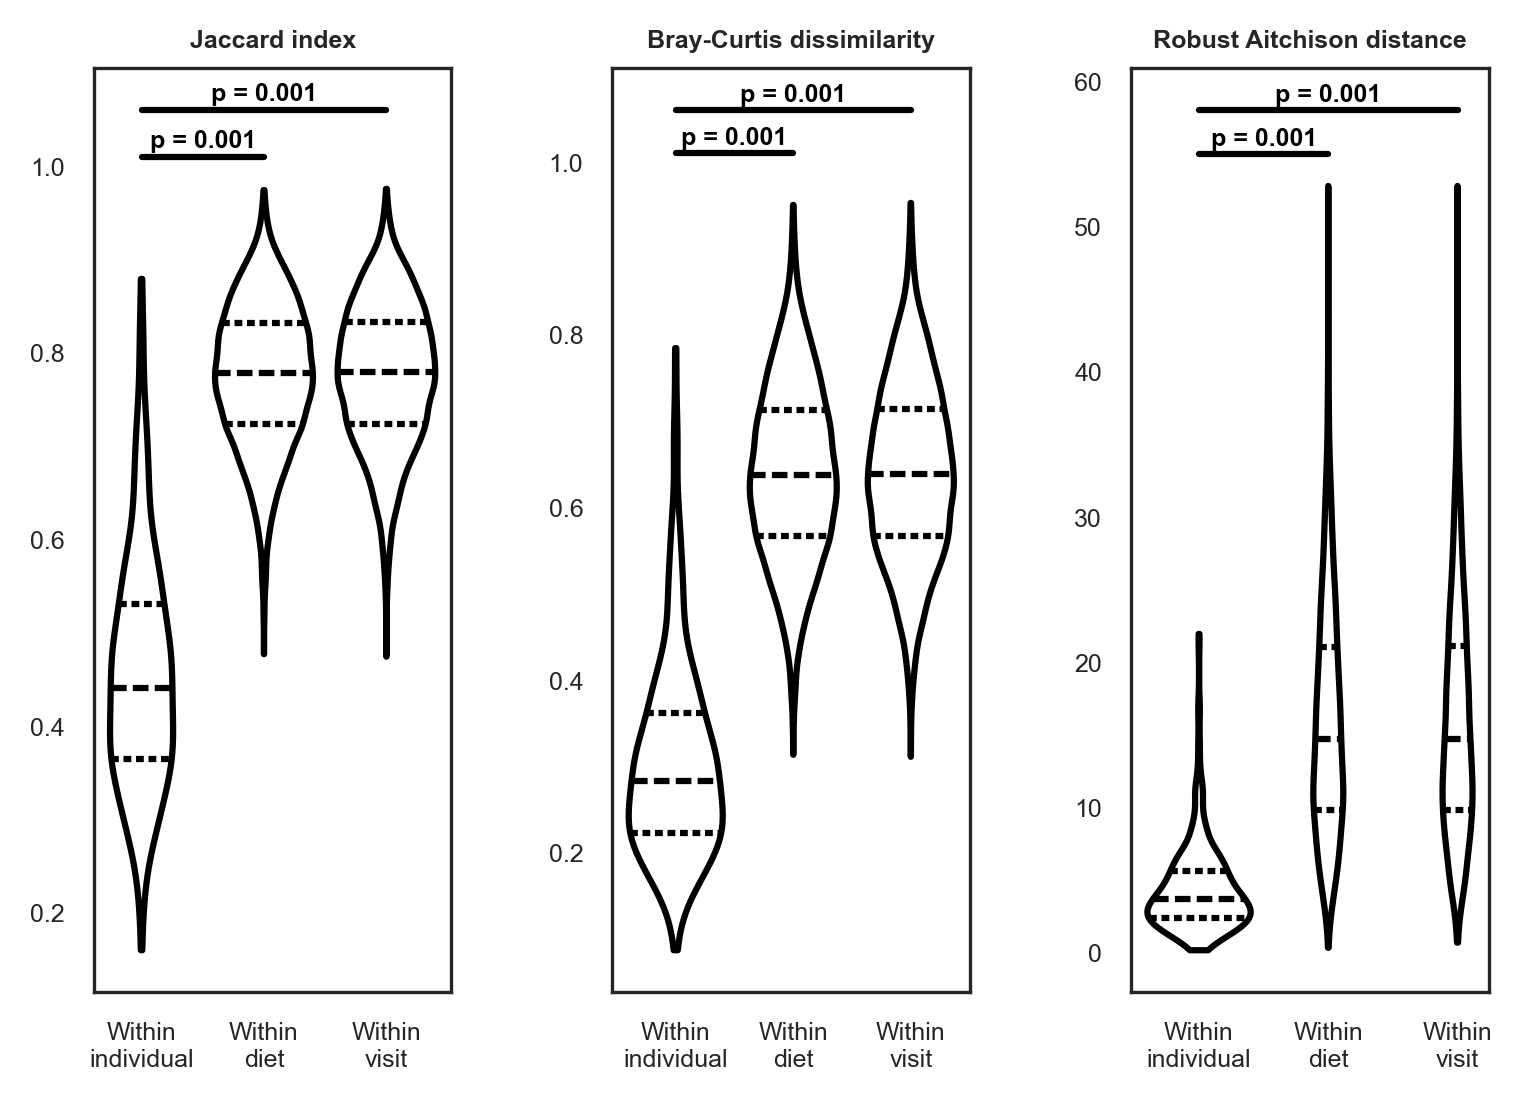

In [38]:
## set up figure and gridspec
supp_fig_ind_distance = plt.figure(figsize=(6, 4), dpi=300)
sns.set_style("white")
supp_fig_ind_distance_gs = supp_fig_ind_distance.add_gridspec(1, 3, wspace=0.45)


supp_fig_ind_distance_jaccard = supp_fig_ind_distance.add_subplot(supp_fig_ind_distance_gs[0])

sns.violinplot(x='group_vis',
               y='value',
               data=ind_covariates_jaccard_comp_df,
               inner='quart',
               fill=False,
               color='black',
               cut=0,
               ax=supp_fig_ind_distance_jaccard)

supp_fig_ind_distance_jaccard.set_title("Jaccard index", fontsize=6, fontweight='bold', pad=5)
supp_fig_ind_distance_jaccard.tick_params(axis='x', labelsize=6)
supp_fig_ind_distance_jaccard.tick_params(axis='y', labelsize=6)
supp_fig_ind_distance_jaccard.set_xlabel("")
supp_fig_ind_distance_jaccard.set_ylabel("")

supp_fig_ind_distance_jaccard.plot([0, 0, 1, 1],
                                   [1.01, 1.01, 1.01, 1.01],
                                   lw=1.5, color='black')

supp_fig_ind_distance_jaccard.text(0.5, 1.015, 'p = 0.001',
                                   ha='center',
                                   va='bottom',
                                   color='black',
                                   fontsize=6,
                                   fontweight='bold')

supp_fig_ind_distance_jaccard.plot([0, 0, 2, 2],
                                   [1.06, 1.06, 1.06, 1.06],
                                   lw=1.5, color='black')

supp_fig_ind_distance_jaccard.text(1, 1.065, 'p = 0.001',
                                   ha='center',
                                   va='bottom',
                                   color='black',
                                   fontsize=6,
                                   fontweight='bold')


supp_fig_ind_distance_bc = supp_fig_ind_distance.add_subplot(supp_fig_ind_distance_gs[1])

sns.violinplot(x='group_vis',
               y='value',
               data=ind_covariates_bc_comp_df,
               inner='quart',
               fill=False,
               color='black',
               cut=0,
               ax=supp_fig_ind_distance_bc)

supp_fig_ind_distance_bc.set_title("Bray-Curtis dissimilarity", fontsize=6, fontweight='bold', pad=5)
supp_fig_ind_distance_bc.tick_params(axis='x', labelsize=6)
supp_fig_ind_distance_bc.tick_params(axis='y', labelsize=6)
supp_fig_ind_distance_bc.set_xlabel("")
supp_fig_ind_distance_bc.set_ylabel("")

supp_fig_ind_distance_bc.plot([0, 0, 1, 1],
                                   [1.01, 1.01, 1.01, 1.01],
                                   lw=1.5, color='black')

supp_fig_ind_distance_bc.text(0.5, 1.015, 'p = 0.001',
                                   ha='center',
                                   va='bottom',
                                   color='black',
                                   fontsize=6,
                                   fontweight='bold')

supp_fig_ind_distance_bc.plot([0, 0, 2, 2],
                                   [1.06, 1.06, 1.06, 1.06],
                                   lw=1.5, color='black')

supp_fig_ind_distance_bc.text(1, 1.065, 'p = 0.001',
                                   ha='center',
                                   va='bottom',
                                   color='black',
                                   fontsize=6,
                                   fontweight='bold')



supp_fig_ind_distance_aitchison = supp_fig_ind_distance.add_subplot(supp_fig_ind_distance_gs[2])

sns.violinplot(x='group_vis',
               y='value',
               data=ind_covariates_aitchison_comp_df,
               inner='quart',
               fill=False,
               color='black',
               cut=0,
               ax=supp_fig_ind_distance_aitchison)

supp_fig_ind_distance_aitchison.set_title("Robust Aitchison distance", fontsize=6, fontweight='bold', pad=5)
supp_fig_ind_distance_aitchison.tick_params(axis='x', labelsize=6)
supp_fig_ind_distance_aitchison.tick_params(axis='y', labelsize=6)
supp_fig_ind_distance_aitchison.set_xlabel("")
supp_fig_ind_distance_aitchison.set_ylabel("")

supp_fig_ind_distance_aitchison.plot([0, 0, 1, 1],
                                   [55, 55, 55, 55],
                                   lw=1.5, color='black')

supp_fig_ind_distance_aitchison.text(0.5, 55.25, 'p = 0.001',
                                   ha='center',
                                   va='bottom',
                                   color='black',
                                   fontsize=6,
                                   fontweight='bold')

supp_fig_ind_distance_aitchison.plot([0, 0, 2, 2],
                                   [58, 58, 58, 58],
                                   lw=1.5, color='black')

supp_fig_ind_distance_aitchison.text(1, 58.25, 'p = 0.001',
                                   ha='center',
                                   va='bottom',
                                   color='black',
                                   fontsize=6,
                                   fontweight='bold')



plt.savefig(f"{PAPER_FIG}/figS3.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{PAPER_FIG}/figS3.pdf", dpi=300, bbox_inches='tight')

### Figure S4 — Differentially abundant taxa (nominal p < 0.05)

In [39]:
## load DA data with all p < 0.05
DASH_p005_all_data = pd.read_csv(f"{DATA}/DASH4D_p005_all_prev_rl.tsv", sep='\t')

In [40]:
DASH_p005_all_data['group_lab'] = \
    DASH_p005_all_data['group'].replace({'DASH4D vs baseline': 'DASH4D diet',
                                         'Comparison vs baseline': 'Comparison diet'})

In [41]:
DASH_p005_all_data['err'] = DASH_p005_all_data['log2fc_ub'] - DASH_p005_all_data['log2fc']

In [42]:
FC_p005_species = DASH_p005_all_data.copy()

In [43]:
FC_p005_species['vis_label_format'] = \
    FC_p005_species['vis_label'].map(format_italic_taxa)
FC_p005_species['vis_label_wrap'] = \
    FC_p005_species.apply(lambda row: f"{row['vis_label_format']} ({row['rl']*100:.2f}%)", axis=1)
FC_p005_species['family'] = \
    FC_p005_species.apply(lambda row: row['vis_label'].split(';')[0], axis=1)


In [44]:
species_p005_df_tobemerged = [
    FC_p005_species[
        FC_p005_species['group_lab'] == 'DASH4D diet'
    ][['taxon', 'family', 'vis_label_wrap', 'log2fc', 'err',
       'p_DASHDASH diet', 'q_DASHDASH diet', 'p_BH']].rename(columns={'log2fc': 'log2fc_dash_baseline',
                                                                      'err': 'err_dash_baseline'}),
    FC_p005_species[
        FC_p005_species['group_lab'] == 'Comparison diet'
    ][['taxon', 'log2fc', 'err']].rename(columns={'log2fc': 'log2fc_comp_baseline',
                                                  'err': 'err_comp_baseline'}),
    FC_p005_species[
        FC_p005_species['group_lab'] == 'DASH4D vs Comparison'
    ][['taxon', 'log2fc', 'err']].rename(columns={'log2fc': 'log2fc_dash_comp',
                                                  'err': 'err_dash_comp'})
]

In [45]:
FC_p005_species_vis_data = \
    merge_taxon_tables(species_p005_df_tobemerged)

In [46]:
FC_p005_species_vis_data.sort_values(by=['log2fc_dash_comp'], inplace=True)

In [47]:
FC_p005_species_vis_data['vis_order'] = range(1, len(FC_p005_species_vis_data) + 1)

In [48]:
FC_p005_species_vis_data['significance_group'] = \
    FC_p005_species_vis_data['p_BH'].case_when(
        [
            (FC_p005_species_vis_data['q_DASHDASH diet'] < 0.05, "holm-adjusted p < 0.05"),
            (FC_p005_species_vis_data['p_BH'] < 0.05, "BH-adjusted p < 0.05"),
            (FC_p005_species_vis_data['p_DASHDASH diet'] < 0.05, "p < 0.05")
        ]
    )

In [49]:
FC_p005_species_vis_p_sig = \
   FC_p005_species_vis_data[
       FC_p005_species_vis_data['significance_group'] == "p < 0.05"
   ]

FC_p005_species_vis_bh_sig = \
   FC_p005_species_vis_data[
       FC_p005_species_vis_data['significance_group'] == "BH-adjusted p < 0.05"
   ]

FC_p005_species_vis_holm_sig = \
   FC_p005_species_vis_data[
       FC_p005_species_vis_data['significance_group'] == "holm-adjusted p < 0.05"
   ]





In [50]:
color_dict = {'DASH4D diet': '#f58518',
              'Comparison diet': '#008080'}

sig_shape_dict = {'p < 0.05': 'o',
                  'BH-adjusted p < 0.05': 's',
                  'holm-adjusted p < 0.05': 'D'}

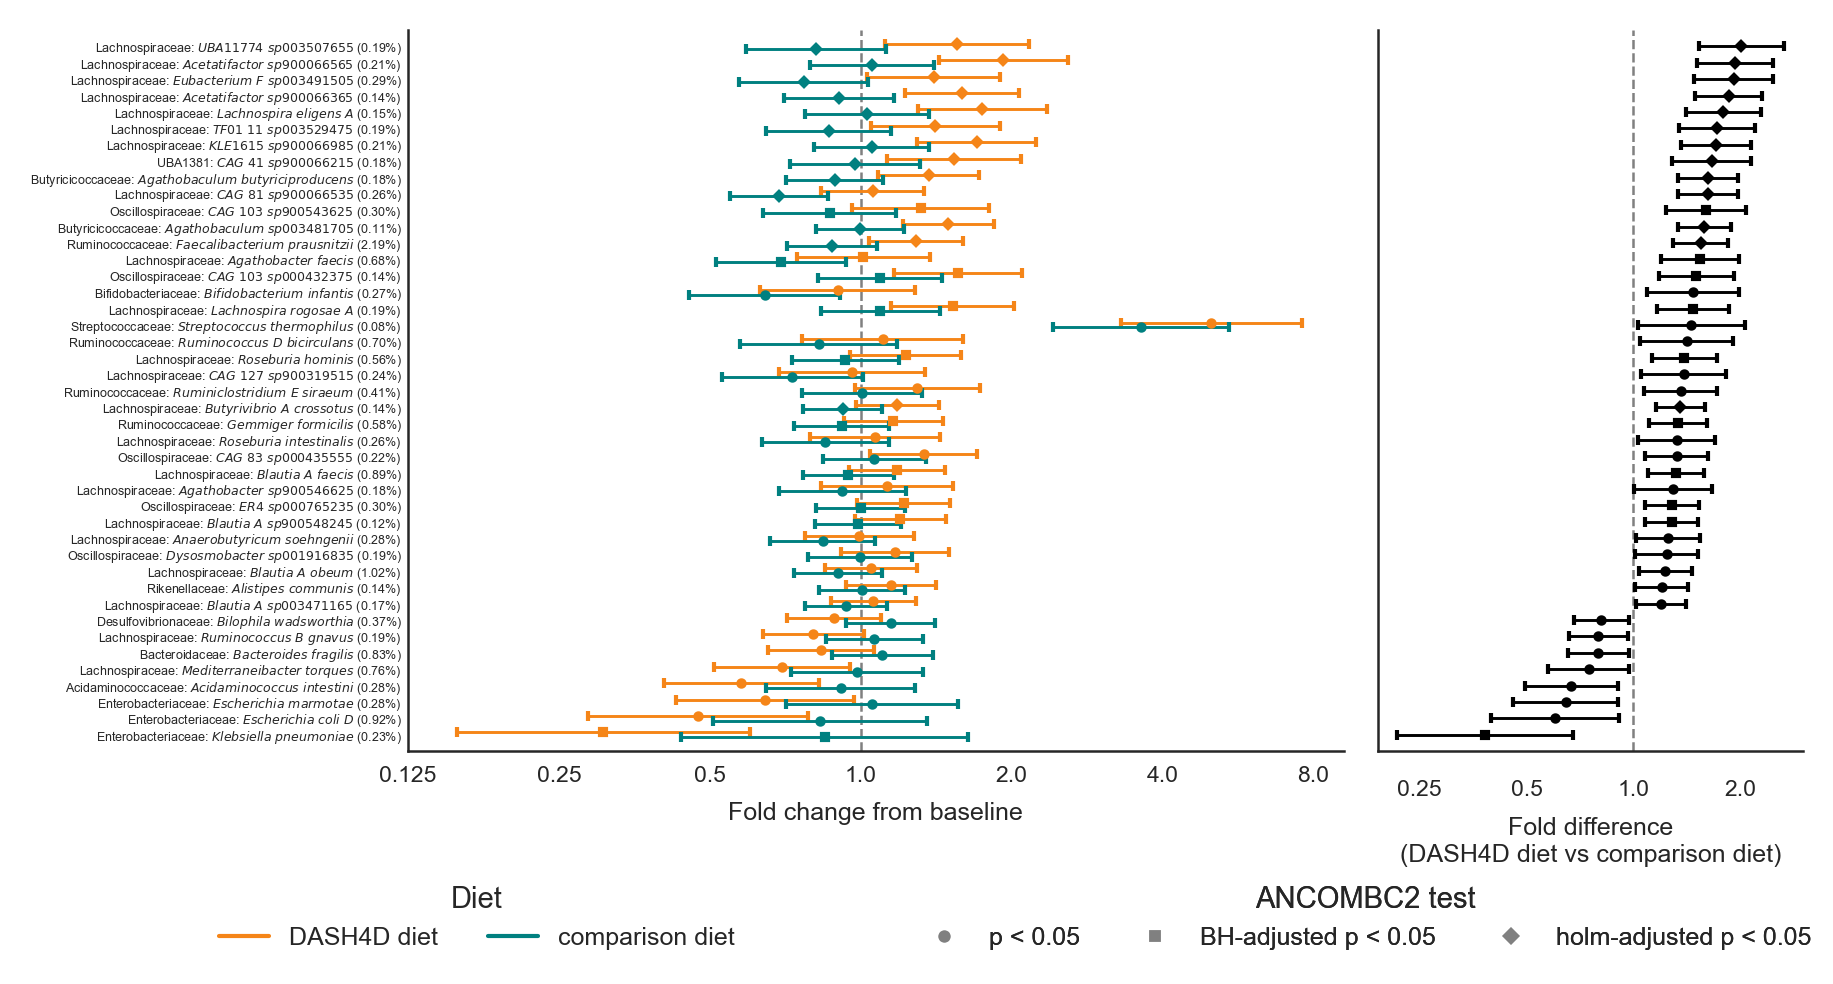

In [51]:
## set up figure and gridspec
fig_DA_p005 = plt.figure(figsize=(6, 4), dpi=300)
sns.set_style("white")
fig_DA_p005_gs = fig_DA_p005.add_gridspec(2, 2,
                                          width_ratios=[2.2,1],
                                          height_ratios=[4, 1],
                                          wspace=0.05,
                                          hspace=0.05)


# p < 0.05 plot: change from baseline panel
fig_DA_p005_frombaseline = fig_DA_p005.add_subplot(fig_DA_p005_gs[0,0])

fig_DA_p005_frombaseline.errorbar(FC_p005_species_vis_p_sig['log2fc_dash_baseline'],
                                  FC_p005_species_vis_p_sig['vis_order'] + 0.15,
                                  xerr=FC_p005_species_vis_p_sig['err_dash_baseline'],
                                  fmt=sig_shape_dict['p < 0.05'],
                                  color=color_dict['DASH4D diet'],
                                  capsize=1.2,
                                  markersize=1.5,
                                  elinewidth=0.7,
                                  zorder=3
                                 )

fig_DA_p005_frombaseline.errorbar(FC_p005_species_vis_p_sig['log2fc_comp_baseline'],
                                  FC_p005_species_vis_p_sig['vis_order'] - 0.15,
                                  xerr=FC_p005_species_vis_p_sig['err_comp_baseline'],
                                  fmt=sig_shape_dict['p < 0.05'],
                                  color=color_dict['Comparison diet'],
                                  capsize=1.2,
                                  markersize=1.5,
                                  elinewidth=0.7,
                                  zorder=3
                                 )

fig_DA_p005_frombaseline.errorbar(FC_p005_species_vis_bh_sig['log2fc_dash_baseline'],
                                  FC_p005_species_vis_bh_sig['vis_order'] + 0.15,
                                  xerr=FC_p005_species_vis_bh_sig['err_dash_baseline'],
                                  fmt=sig_shape_dict['BH-adjusted p < 0.05'],
                                  color=color_dict['DASH4D diet'],
                                  capsize=1.2,
                                  markersize=1.5,
                                  elinewidth=0.7,
                                  zorder=3
                                 )

fig_DA_p005_frombaseline.errorbar(FC_p005_species_vis_bh_sig['log2fc_comp_baseline'],
                                  FC_p005_species_vis_bh_sig['vis_order'] - 0.15,
                                  xerr=FC_p005_species_vis_bh_sig['err_comp_baseline'],
                                  fmt=sig_shape_dict['BH-adjusted p < 0.05'],
                                  color=color_dict['Comparison diet'],
                                  capsize=1.2,
                                  markersize=1.5,
                                  elinewidth=0.7,
                                  zorder=3
                                 )

fig_DA_p005_frombaseline.errorbar(FC_p005_species_vis_holm_sig['log2fc_dash_baseline'],
                                  FC_p005_species_vis_holm_sig['vis_order'] + 0.15,
                                  xerr=FC_p005_species_vis_holm_sig['err_dash_baseline'],
                                  fmt=sig_shape_dict['holm-adjusted p < 0.05'],
                                  color=color_dict['DASH4D diet'],
                                  capsize=1.2,
                                  markersize=1.5,
                                  elinewidth=0.7,
                                  zorder=3
                                 )

fig_DA_p005_frombaseline.errorbar(FC_p005_species_vis_holm_sig['log2fc_comp_baseline'],
                                  FC_p005_species_vis_holm_sig['vis_order'] - 0.15,
                                  xerr=FC_p005_species_vis_holm_sig['err_comp_baseline'],
                                  fmt=sig_shape_dict['holm-adjusted p < 0.05'],
                                  color=color_dict['Comparison diet'],
                                  capsize=1.2,
                                  markersize=1.5,
                                  elinewidth=0.7,
                                  zorder=3
                                 )

# set up taxonomy labels
fig_DA_p005_frombaseline.set_ylim((FC_p005_species_vis_data['vis_order'].min() - 1,
                                   FC_p005_species_vis_data['vis_order'].max() + 1))
fig_DA_p005_frombaseline.set_yticks(FC_p005_species_vis_data['vis_order'])
fig_DA_p005_frombaseline.set_yticklabels(FC_p005_species_vis_data['vis_label_wrap'],
                                         ha='right',
                                         fontsize=3,
                                        )
fig_DA_p005_frombaseline.tick_params(axis='y', pad=0, length=1.5)
fig_DA_p005_frombaseline.tick_params(axis='x', pad=0)
fig_DA_p005_frombaseline.set_xticks([-3,-2,-1,0,1,2,3])
fig_DA_p005_frombaseline.set_xticklabels(["0.125", "0.25", "0.5", "1.0", "2.0", "4.0", "8.0"])
fig_DA_p005_frombaseline.set_xlabel("Fold change from baseline", fontsize=6)


# p < 0.05 plot: DID panel
fig_DA_p005_DID = fig_DA_p005.add_subplot(fig_DA_p005_gs[0,1],
                                   sharey=fig_DA_p005_frombaseline)



fig_DA_p005_DID.errorbar(FC_p005_species_vis_p_sig['log2fc_dash_comp'],
                         FC_p005_species_vis_p_sig['vis_order'],
                         xerr=FC_p005_species_vis_p_sig['err_dash_comp'],
                         fmt=sig_shape_dict['p < 0.05'],
                         color='black',
                         capsize=1.2,
                         markersize=1.5,
                         elinewidth=0.7,
                         zorder=3
                        )

fig_DA_p005_DID.errorbar(FC_p005_species_vis_bh_sig['log2fc_dash_comp'],
                         FC_p005_species_vis_bh_sig['vis_order'],
                         xerr=FC_p005_species_vis_bh_sig['err_dash_comp'],
                         fmt=sig_shape_dict['BH-adjusted p < 0.05'],
                         color='black',
                         capsize=1.2,
                         markersize=1.5,
                         elinewidth=0.7,
                         zorder=3
                        )

fig_DA_p005_DID.errorbar(FC_p005_species_vis_holm_sig['log2fc_dash_comp'],
                         FC_p005_species_vis_holm_sig['vis_order'],
                         xerr=FC_p005_species_vis_holm_sig['err_dash_comp'],
                         fmt=sig_shape_dict['holm-adjusted p < 0.05'],
                         color='black',
                         capsize=1.2,
                         markersize=1.5,
                         elinewidth=0.7,
                         zorder=3
                        )

fig_DA_p005_DID.set_xlabel("Fold difference\n(DASH4D diet vs comparison diet)", fontsize=6)
fig_DA_p005_DID.set_xticks([-2,-1,0,1])
fig_DA_p005_DID.set_xticklabels(["0.25", "0.5", "1.0", "2.0"])



for ax in [fig_DA_p005_frombaseline, fig_DA_p005_DID]:
    ax.axvline(0, color='grey', lw=0.6, ls='--', zorder=2)
    ax.tick_params(axis='x', labelsize=5.5)
    sns.despine(ax=ax)
    for s in ax.spines.values(): s.set_linewidth(0.6)

plt.setp(fig_DA_p005_DID.get_yticklabels(), visible=False)

## plot legend

fig_DA_p005_legend = fig_DA_p005.add_subplot(fig_DA_p005_gs[1,:])

fig_DA_p005_legend.axis('off')
color_legend_elements = [Line2D([0], [0],
                                color=color_dict['DASH4D diet'],
                                lw=1, label='DASH4D diet'),
                         Line2D([0], [0],
                                color=color_dict['Comparison diet'], lw=1, label='comparison diet')]

shape_legend_elements = [
    Line2D([0], [0],
           marker=sig_shape_dict['p < 0.05'],
           color='w',
           markerfacecolor='gray',
           markersize=4,
           label='p < 0.05'),
    Line2D([0], [0],
           marker=sig_shape_dict['BH-adjusted p < 0.05'],
           color='w',
           markerfacecolor='gray',
           markersize=4,
           label='BH-adjusted p < 0.05'),
    Line2D([0], [0],
           marker=sig_shape_dict['holm-adjusted p < 0.05'],
           color='w',
           markerfacecolor='gray',
           markersize=4,
           label='holm-adjusted p < 0.05')
]

fig_DA_p005_color_legend = \
    fig_DA_p005_legend.legend(handles=color_legend_elements,
                              title='Diet',
                              frameon=False,
                              bbox_to_anchor=(0.25,0.5),
                              ncol=2,
                              fontsize=6,
                              title_fontsize=7)

fig_DA_p005_legend.add_artist(fig_DA_p005_color_legend)


fig_DA_p005_shape_legend = \
    fig_DA_p005_legend.legend(handles=shape_legend_elements,
                              title='ANCOMBC2 test',
                              loc='upper left',
                              frameon=False,
                              bbox_to_anchor=(0.35,0.5),
                              ncol=3,
                              fontsize=6,
                              title_fontsize=7)

fig_DA_p005_legend.add_artist(fig_DA_p005_shape_legend)


plt.savefig(f"{PAPER_FIG}/figS4.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{PAPER_FIG}/figS4.pdf", dpi=300, bbox_inches='tight')
plt.show()

### Figures S5–S6 — Microbiome associations with clinical outcomes

The following tables and display labels are shared between Figures S5 and S6.

In [52]:
## read baseline SBP and microbe
baseline_SBP_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/baseline_feature_SBP_marginal.tsv", sep='\t')
## read baseline DBP and microbe
baseline_DBP_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/baseline_feature_DBP_marginal.tsv", sep='\t')

In [53]:
## read baseline fasting glucose and microbe
baseline_fg_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/baseline_feature_fasting_glucose_marginal.tsv", sep='\t')
## read baseline fructosamine and microbe
baseline_fructosamine_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/baseline_feature_fructosamine_marginal.tsv", sep='\t')
## read baseline HOMA-IR and microbe
baseline_log_HOMA_IR_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/baseline_feature_log_HOMA_IR_marginal.tsv", sep='\t')

In [54]:
## read change in SBP and microbe
change_SBP_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/change_feature_SBP_marginal.tsv", sep='\t')
## read change in DBP and microbe
change_DBP_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/change_feature_DBP_marginal.tsv", sep='\t')

In [55]:
## read change in fasting glucose and change in microbe
change_fg_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/change_feature_fasting_glucose_marginal.tsv", sep='\t')
change_fructosamine_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/change_feature_fructosamine_marginal.tsv", sep='\t')
change_log_HOMA_IR_microbe = \
    pd.read_csv(f"{INTERMEDIATE_MICRO}/change_feature_log_HOMA_IR_marginal.tsv", sep='\t')

In [56]:
baseline_SBP_microbe['vis_order'] = np.arange(8,0,-1)
baseline_SBP_microbe['err'] = baseline_SBP_microbe['ub'] - baseline_SBP_microbe['est']
baseline_DBP_microbe['vis_order'] = np.arange(8,0,-1)
baseline_DBP_microbe['err'] = baseline_DBP_microbe['ub'] - baseline_DBP_microbe['est']
baseline_fg_microbe['vis_order'] = np.arange(8,0,-1)
baseline_fg_microbe['err'] = baseline_fg_microbe['ub'] - baseline_fg_microbe['est']
baseline_fructosamine_microbe['vis_order'] = np.arange(8,0,-1)
baseline_fructosamine_microbe['err'] = baseline_fructosamine_microbe['ub'] - baseline_fructosamine_microbe['est']
baseline_log_HOMA_IR_microbe['vis_order'] = np.arange(8,0,-1)
baseline_log_HOMA_IR_microbe['err'] = np.exp2(baseline_log_HOMA_IR_microbe['ub']) - np.exp2(baseline_log_HOMA_IR_microbe['est'])
baseline_log_HOMA_IR_microbe['est'] = np.exp2(baseline_log_HOMA_IR_microbe['est'])


change_SBP_microbe['vis_order'] = np.arange(8,0,-1)
change_SBP_microbe['err'] = change_SBP_microbe['ub'] - change_SBP_microbe['est']
change_DBP_microbe['vis_order'] = np.arange(8,0,-1)
change_DBP_microbe['err'] = change_DBP_microbe['ub'] - change_DBP_microbe['est']

change_fg_microbe['vis_order'] = np.arange(8,0,-1)
change_fg_microbe['err'] = change_fg_microbe['ub'] - change_fg_microbe['est']
change_fructosamine_microbe['vis_order'] = np.arange(8,0,-1)
change_fructosamine_microbe['err'] = change_fructosamine_microbe['ub'] - change_fructosamine_microbe['est']
change_log_HOMA_IR_microbe['vis_order'] = np.arange(8,0,-1)
change_log_HOMA_IR_microbe['err'] = np.exp2(change_log_HOMA_IR_microbe['ub']) - np.exp2(change_log_HOMA_IR_microbe['est'])
change_log_HOMA_IR_microbe['est'] = np.exp2(change_log_HOMA_IR_microbe['est'])


In [57]:
change_DBP_microbe

,Feature,est,lb,ub,pval,vis_order,err
0,DASH4D microbe index,0.138581,-0.414925,0.692886,0.625241,8,0.554304
1,Shannon,0.314860,-0.269117,0.899242,0.293422,7,0.584382
2,log2(Butyrate producer),0.467984,-0.104258,1.039507,0.110834,6,0.571523
3,log2(F. prausnitzii),0.046466,-0.526451,0.619312,0.874355,5,0.572847
4,But gene,0.063856,-0.447449,0.575606,0.807662,4,0.511751
5,EtfA gene,0.159852,-0.346981,0.667138,0.538805,3,0.507286
6,EtfB gene,-0.009857,-0.521640,0.501916,0.970046,2,0.511773
7,Acetyl-CoA pathway,0.352509,-0.189275,0.893555,0.204423,1,0.541045


In [58]:
baseline_fg_microbe['Feature'] = \
    baseline_fg_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F.prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "log2(But gene per 1 million reads)": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "log2(EtfA gene per 1 million reads)": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "log2(EtfB gene per 1 million reads)": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "log2(Acetyl-CoA pathway per 1 million reads)" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                            
                                           }
                                          )
baseline_SBP_microbe['Feature'] = \
    baseline_SBP_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F. prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "log2(But gene per 1 million reads)": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "log2(EtfA gene per 1 million reads)": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "log2(EtfB gene per 1 million reads)": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "log2(Acetyl-CoA pathway per 1 million reads)" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                           }
                                          )

baseline_DBP_microbe['Feature'] = \
    baseline_DBP_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F. prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "log2(But gene per 1 million reads)": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "log2(EtfA gene per 1 million reads)": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "log2(EtfB gene per 1 million reads)": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "log2(Acetyl-CoA pathway per 1 million reads)" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                           }
                                          )

baseline_fructosamine_microbe['Feature'] = \
    baseline_fructosamine_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F. prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "log2(But gene per 1 million reads)": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "log2(EtfA gene per 1 million reads)": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "log2(EtfB gene per 1 million reads)": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "log2(Acetyl-CoA pathway per 1 million reads)" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                           }
                                          )

baseline_log_HOMA_IR_microbe['Feature'] = \
    baseline_log_HOMA_IR_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F. prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "log2(But gene per 1 million reads)": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "log2(EtfA gene per 1 million reads)": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "log2(EtfB gene per 1 million reads)": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "log2(Acetyl-CoA pathway per 1 million reads)" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                           }
                                          )


change_fg_microbe['Feature'] = \
    change_fg_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F. prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "But gene": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "EtfA gene": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "EtfB gene": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "Acetyl-CoA pathway" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                           }
                                          )
change_SBP_microbe['Feature'] = \
    change_SBP_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F. prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "But gene": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "EtfA gene": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "EtfB gene": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "Acetyl-CoA pathway" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                           }
                                          )

change_DBP_microbe['Feature'] = \
    change_DBP_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F. prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "But gene": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "EtfA gene": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "EtfB gene": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "Acetyl-CoA pathway" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                           }
                                          )

change_fructosamine_microbe['Feature'] = \
    change_fructosamine_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F. prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "But gene": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "EtfA gene": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "EtfB gene": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "Acetyl-CoA pathway" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                           }
                                          )

change_log_HOMA_IR_microbe['Feature'] = \
    change_log_HOMA_IR_microbe['Feature'].replace({"DASH4D microbe index": "DASH4D Microbe Index",
                                            "Shannon": "Shannon Diversity",
                                            "log2(Butyrate producer)": r"log$_2$(Butyrate Producer)",
                                            "log2(F. prausnitzii)": r"log$_2$($\it{F.\ prausnitzii}$)",
                                            "But gene": r"log$_2$($\it{but}$ Gene, per Million Reads)",
                                            "EtfA gene": r"log$_2$($\it{eftA}$ Gene, per Million Reads)",
                                            "EtfB gene": r"log$_2$($\it{eftB}$ Gene, per Million Reads)",
                                            "Acetyl-CoA pathway" : r"log$_2$(Acetyl-CoA pathway, per Million Reads)"
                                           }
                                          )

#### Figure S5 — Blood pressure outcomes

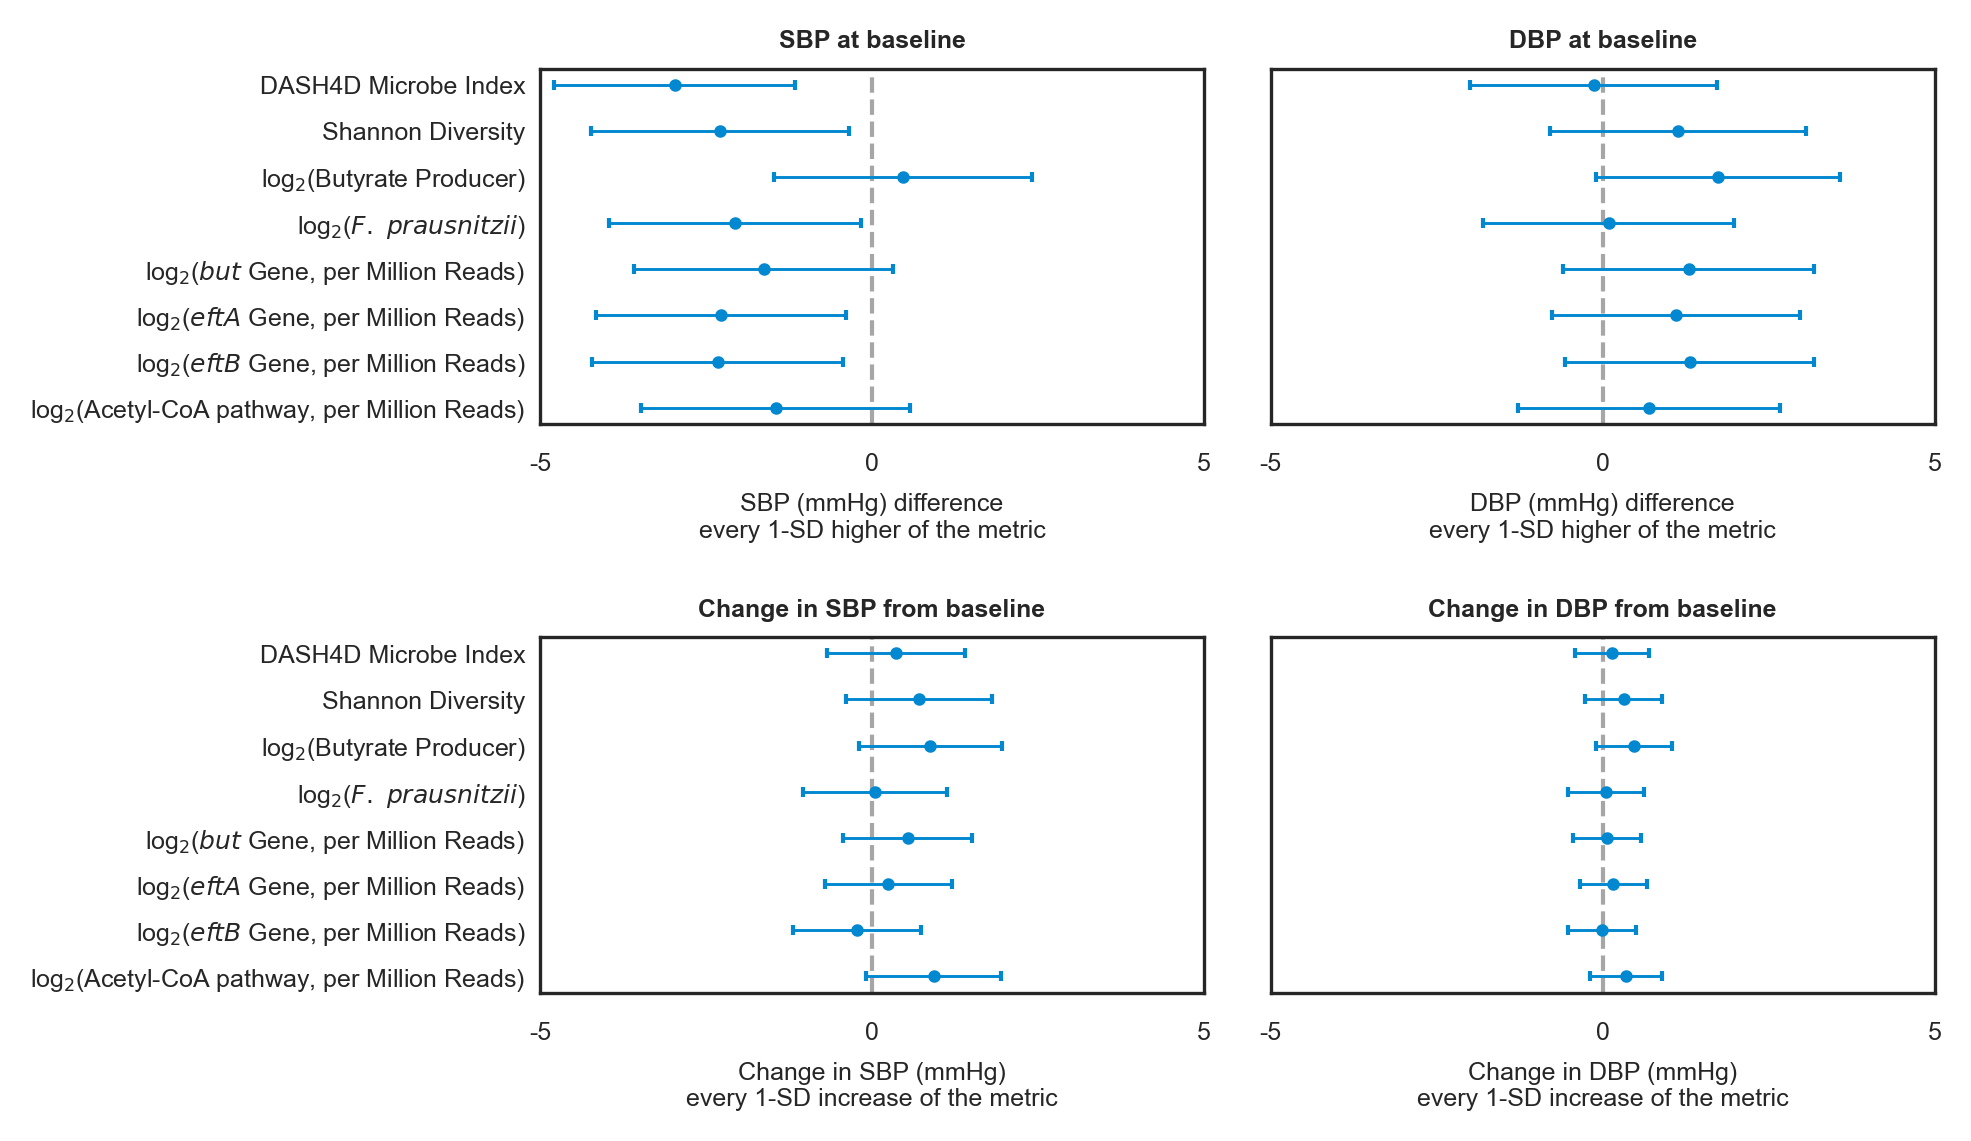

In [59]:
## set up figure and gridspec
## set up figure and gridspec
figBP = plt.figure(figsize=(6, 4), dpi=300)
sns.set_style("white")
figBP_gs = figBP.add_gridspec(2, 2, wspace=0.1, hspace=0.6)

figBP_baseline_SBP = figBP.add_subplot(figBP_gs[0, 0])

figBP_baseline_SBP.errorbar(baseline_SBP_microbe['est'],
                     baseline_SBP_microbe['vis_order'],
                     xerr=baseline_SBP_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figBP_baseline_SBP.set_yticks(baseline_SBP_microbe['vis_order'])
figBP_baseline_SBP.set_yticklabels(baseline_SBP_microbe['Feature'], fontsize=6)
figBP_baseline_SBP.set_title("SBP at baseline", fontsize=6, fontweight='bold', pad=5)
figBP_baseline_SBP.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figBP_baseline_SBP.set_xlabel("SBP (mmHg) difference\nevery 1-SD higher of the metric", fontsize=6)
figBP_baseline_SBP.set_xlim(-5, 5)
figBP_baseline_SBP.set_xticks([-5,0,5])
figBP_baseline_SBP.set_xticklabels([-5,0,5], fontsize=6)
figBP_baseline_SBP.tick_params(axis='y', pad=0)



figBP_change_SBP = figBP.add_subplot(figBP_gs[1, 0])

figBP_change_SBP.errorbar(change_SBP_microbe['est'],
                     change_SBP_microbe['vis_order'],
                     xerr=change_SBP_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figBP_change_SBP.set_yticks(change_SBP_microbe['vis_order'])
figBP_change_SBP.set_yticklabels(change_SBP_microbe['Feature'], fontsize=6)
figBP_change_SBP.set_title("Change in SBP from baseline", fontsize=6, fontweight='bold', pad=5)
figBP_change_SBP.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figBP_change_SBP.set_xlabel("Change in SBP (mmHg)\nevery 1-SD increase of the metric", fontsize=6)
figBP_change_SBP.set_xlim(-5, 5)
figBP_change_SBP.set_xticks([-5,0,5])
figBP_change_SBP.set_xticklabels([-5,0,5], fontsize=6)
figBP_change_SBP.tick_params(axis='y', pad=0)

figBP_baseline_DBP = figBP.add_subplot(figBP_gs[0, 1])

figBP_baseline_DBP.errorbar(baseline_DBP_microbe['est'],
                     baseline_DBP_microbe['vis_order'],
                     xerr=baseline_DBP_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figBP_baseline_DBP.set_yticks(baseline_DBP_microbe['vis_order'])
figBP_baseline_DBP.set_yticklabels("", fontsize=6)
figBP_baseline_DBP.set_title("DBP at baseline", fontsize=6, fontweight='bold', pad=5)
figBP_baseline_DBP.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figBP_baseline_DBP.set_xlabel("DBP (mmHg) difference\nevery 1-SD higher of the metric", fontsize=6)
figBP_baseline_DBP.set_xlim(-5, 5)
figBP_baseline_DBP.set_xticks([-5, 0, 5])
figBP_baseline_DBP.set_xticklabels([-5, 0, 5], fontsize=6)
figBP_baseline_DBP.tick_params(axis='y', pad=0)

figBP_change_DBP = figBP.add_subplot(figBP_gs[1, 1])

figBP_change_DBP.errorbar(change_DBP_microbe['est'],
                     change_DBP_microbe['vis_order'],
                     xerr=change_DBP_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figBP_change_DBP.set_yticks(change_DBP_microbe['vis_order'])
figBP_change_DBP.set_yticklabels("", fontsize=6)
figBP_change_DBP.set_title("Change in DBP from baseline", fontsize=6, fontweight='bold', pad=5)
figBP_change_DBP.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figBP_change_DBP.set_xlabel("Change in DBP (mmHg)\nevery 1-SD increase of the metric", fontsize=6)
figBP_change_DBP.set_xlim(-5, 5)
figBP_change_DBP.set_xticks([-5,0,5])
figBP_change_DBP.set_xticklabels([-5,0,5], fontsize=6)
figBP_change_DBP.tick_params(axis='y', pad=0)


plt.savefig(f"{PAPER_FIG}/figS5.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{PAPER_FIG}/figS5.pdf", dpi=300, bbox_inches='tight')

#### Figure S6 — Glycemic outcomes

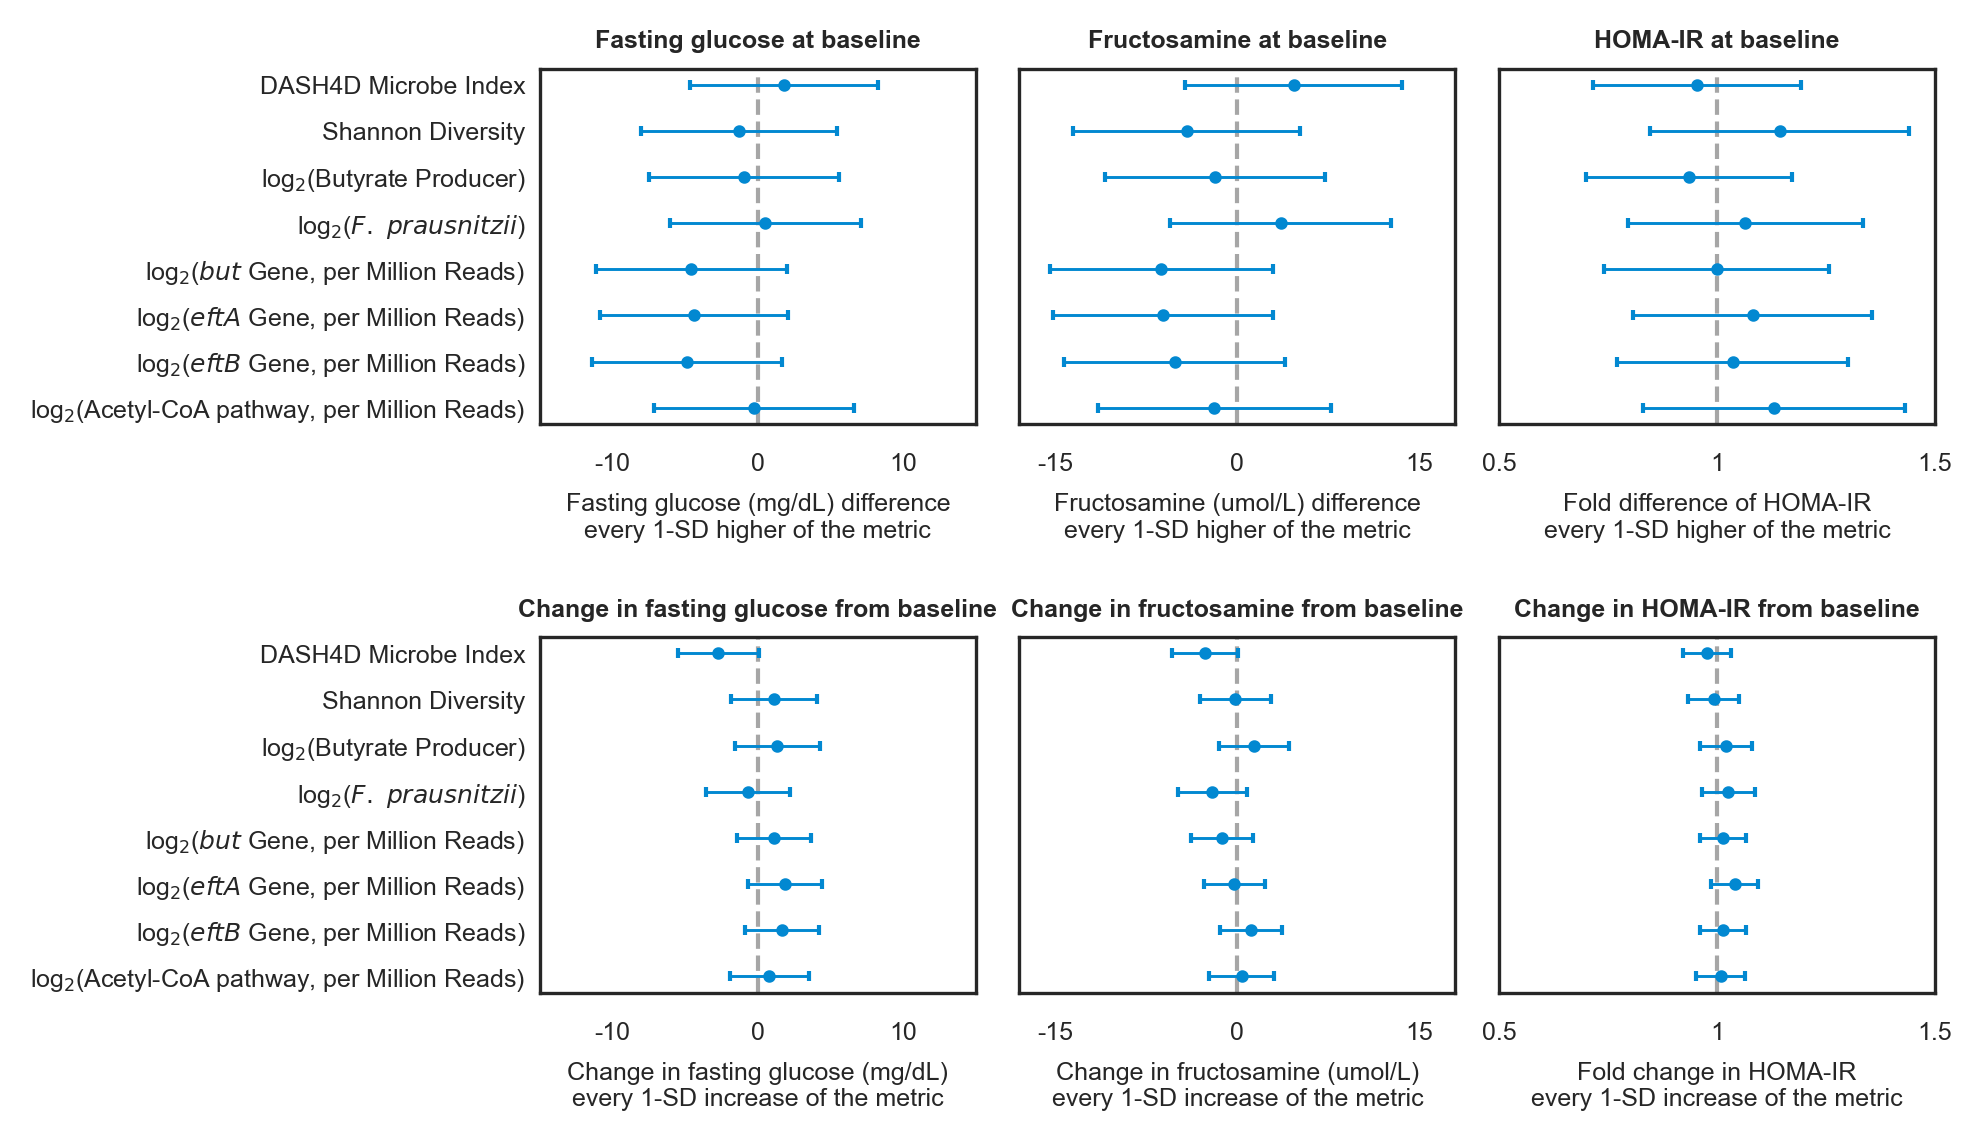

In [60]:
## set up figure and gridspec
figglucose = plt.figure(figsize=(6, 4), dpi=300)
sns.set_style("white")
figglucose_gs = figglucose.add_gridspec(2, 3, wspace=0.1, hspace=0.6)

figglucose_baseline_fg = figglucose.add_subplot(figglucose_gs[0, 0])

figglucose_baseline_fg.errorbar(baseline_fg_microbe['est'],
                     baseline_fg_microbe['vis_order'],
                     xerr=baseline_fg_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figglucose_baseline_fg.set_yticks(baseline_fg_microbe['vis_order'])
figglucose_baseline_fg.set_yticklabels(baseline_fg_microbe['Feature'], fontsize=6)
figglucose_baseline_fg.set_title("Fasting glucose at baseline", fontsize=6, fontweight='bold', pad=5)
figglucose_baseline_fg.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figglucose_baseline_fg.set_xlabel("Fasting glucose (mg/dL) difference\nevery 1-SD higher of the metric", fontsize=6)
figglucose_baseline_fg.set_xlim(-15, 15)
figglucose_baseline_fg.set_xticks([-10, 0, 10])
figglucose_baseline_fg.set_xticklabels([-10, 0, 10], fontsize=6)
figglucose_baseline_fg.tick_params(axis='y', pad=0)

figglucose_change_fg = figglucose.add_subplot(figglucose_gs[1, 0])

figglucose_change_fg.errorbar(change_fg_microbe['est'],
                     change_fg_microbe['vis_order'],
                     xerr=change_fg_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figglucose_change_fg.set_yticks(change_fg_microbe['vis_order'])
figglucose_change_fg.set_yticklabels(change_fg_microbe['Feature'], fontsize=6)
figglucose_change_fg.set_title("Change in fasting glucose from baseline", fontsize=6, fontweight='bold', pad=5)
figglucose_change_fg.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figglucose_change_fg.set_xlabel("Change in fasting glucose (mg/dL)\nevery 1-SD increase of the metric", fontsize=6)
figglucose_change_fg.set_xlim(-15, 15)
figglucose_change_fg.set_xticks([-10,0,10])
figglucose_change_fg.set_xticklabels([-10,0,10], fontsize=6)
figglucose_change_fg.tick_params(axis='y', pad=0)

figglucose_baseline_fructosamine = figglucose.add_subplot(figglucose_gs[0, 1])

figglucose_baseline_fructosamine.errorbar(baseline_fructosamine_microbe['est'],
                     baseline_fructosamine_microbe['vis_order'],
                     xerr=baseline_fructosamine_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figglucose_baseline_fructosamine.set_yticks(baseline_fructosamine_microbe['vis_order'])
figglucose_baseline_fructosamine.set_yticklabels("", fontsize=6)
figglucose_baseline_fructosamine.set_title("Fructosamine at baseline", fontsize=6, fontweight='bold', pad=5)
figglucose_baseline_fructosamine.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figglucose_baseline_fructosamine.set_xlabel("Fructosamine (umol/L) difference\nevery 1-SD higher of the metric", fontsize=6)
figglucose_baseline_fructosamine.set_xlim(-18, 18)
figglucose_baseline_fructosamine.set_xticks([-15,0,15])
figglucose_baseline_fructosamine.set_xticklabels([-15,0,15], fontsize=6)
figglucose_baseline_fructosamine.tick_params(axis='y', pad=0)



figglucose_change_fructosamine = figglucose.add_subplot(figglucose_gs[1, 1])

figglucose_change_fructosamine.errorbar(change_fructosamine_microbe['est'],
                     change_fructosamine_microbe['vis_order'],
                     xerr=change_fructosamine_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figglucose_change_fructosamine.set_yticks(change_fructosamine_microbe['vis_order'])
figglucose_change_fructosamine.set_yticklabels("", fontsize=6)
figglucose_change_fructosamine.set_title("Change in fructosamine from baseline", fontsize=6, fontweight='bold', pad=5)
figglucose_change_fructosamine.axvline(x=0, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figglucose_change_fructosamine.set_xlabel("Change in fructosamine (umol/L)\nevery 1-SD increase of the metric", fontsize=6)
figglucose_change_fructosamine.set_xlim(-18, 18)
figglucose_change_fructosamine.set_xticks([-15,0,15])
figglucose_change_fructosamine.set_xticklabels([-15,0,15], fontsize=6)
figglucose_change_fructosamine.tick_params(axis='y', pad=0)

figglucose_baseline_log_HOMA_IR = figglucose.add_subplot(figglucose_gs[0, 2])

figglucose_baseline_log_HOMA_IR.errorbar(baseline_log_HOMA_IR_microbe['est'],
                     baseline_log_HOMA_IR_microbe['vis_order'],
                     xerr=baseline_log_HOMA_IR_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figglucose_baseline_log_HOMA_IR.set_yticks(baseline_log_HOMA_IR_microbe['vis_order'])
figglucose_baseline_log_HOMA_IR.set_yticklabels("", fontsize=6)
figglucose_baseline_log_HOMA_IR.set_title("HOMA-IR at baseline", fontsize=6, fontweight='bold', pad=5)
figglucose_baseline_log_HOMA_IR.axvline(x=1, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figglucose_baseline_log_HOMA_IR.set_xlabel("Fold difference of HOMA-IR\nevery 1-SD higher of the metric", fontsize=6)
figglucose_baseline_log_HOMA_IR.set_xlim(0.5,1.5)
figglucose_baseline_log_HOMA_IR.set_xticks([0.5, 1, 1.5])
figglucose_baseline_log_HOMA_IR.set_xticklabels([0.5, 1, 1.5], fontsize=6)
figglucose_baseline_log_HOMA_IR.tick_params(axis='y', pad=0)



figglucose_change_log_HOMA_IR = figglucose.add_subplot(figglucose_gs[1, 2])

figglucose_change_log_HOMA_IR.errorbar(change_log_HOMA_IR_microbe['est'],
                     change_log_HOMA_IR_microbe['vis_order'],
                     xerr=change_log_HOMA_IR_microbe['err'],
                     fmt='o',
                     capsize=1.2,
                     color='#0288D1',
                     markersize=2,
                     elinewidth=0.7,
                     zorder=3
                    )

figglucose_change_log_HOMA_IR.set_yticks(change_log_HOMA_IR_microbe['vis_order'])
figglucose_change_log_HOMA_IR.set_yticklabels("", fontsize=6)
figglucose_change_log_HOMA_IR.set_title("Change in HOMA-IR from baseline", fontsize=6, fontweight='bold', pad=5)
figglucose_change_log_HOMA_IR.axvline(x=1, color='gray', linestyle='--', linewidth=1, alpha=0.7)
figglucose_change_log_HOMA_IR.set_xlabel("Fold change in HOMA-IR\nevery 1-SD increase of the metric", fontsize=6)
figglucose_change_log_HOMA_IR.set_xlim(0.5, 1.5)
figglucose_change_log_HOMA_IR.set_xticks([0.5, 1, 1.5])
figglucose_change_log_HOMA_IR.set_xticklabels([0.5, 1, 1.5], fontsize=6)
figglucose_change_log_HOMA_IR.tick_params(axis='y', pad=0)

plt.savefig(f"{PAPER_FIG}/figS6.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{PAPER_FIG}/figS6.pdf", dpi=300, bbox_inches='tight')

### Shared forest-plot helper for Figures S7–S10

In [61]:
def forest_plot_subgroup(
    df,
    p_val_dict,
    x_axis_label,
    filename,
    figure_size=(6,4),
    dpi=300,
    null_line=0,
    group_multi=1,
    var_multi=1.4,
    p_multi=1.2,
    customize_param=None,
):
    """
    Create forest plot based on formatted dataframe and parameters

    Args:
        df: pd.DataFrame         # the input dataframe
           Variable: Variable name to be stratified
           Group: Group name of the variable
           N: # in the group
           Est: the estimate in the group
           lb: lb
           ub: ub
           p: p value for the interaction
        p_val_dict: dict         # the data dictionary for variable name and p value print
        x_axis_label: str        # the x axis label
        filename: str            # the output filename without ext
        figure_size: tuple       # a tuple with height and width for the figure. Default: (6,4)
        dpi: int                 # dpi for the figure. Default: 300
        null_line: int           # the x axis for the null vertical line. Default: 0
        group_multi: float       # the factor for the distance between group column to n column. Default: 1
        var_multi: float         # the factor for the distance between variable column to group column. Default: 1.4
        p_multi: float           # the factor for the distance between p column to est column. Default: 1.2
        customize_param: dict    # the customized parameter data dictionary

    Side effects:
        Generate the forest plot and export to file

    Returns:
        None
        
    """
    ## set up figures
    fig, ax = plt.subplots(figsize=figure_size,
                           dpi=dpi)

    

    ## Define X-axis positions for text columns
    if customize_param is None:
        ## set up x position for each column category
        left_x = np.floor(min(df.lb))
        right_x = np.ceil(max(df.ub))

        ## define x axis sequence difference
        range_all = right_x - left_x

        if range_all < 20:
            x_axis_gap = 2
        elif range_all < 30:
            x_axis_gap = 5
        else:
            x_axis_gap = 10
        
        pos_n = left_x - ((range_all // 10) + 1)*0.5
        pos_group = pos_n - ((range_all // 10) + 1)*group_multi
        pos_var = pos_group - ((range_all // 10) + 1)*var_multi
        pos_est_text = right_x + ((range_all // 10)+1)*0.8
        pos_p = pos_est_text + ((range_all // 10)+1)*p_multi

        x_axis_tick_label = np.arange(
            np.ceil(left_x/x_axis_gap)*x_axis_gap,
            (np.floor(right_x/x_axis_gap) + 1)*x_axis_gap,
            x_axis_gap
        )
        
    else:
        left_x = customize_param['left_x']
        right_x = customize_param['right_x']
        
        pos_n = customize_param['pos_n']
        pos_group = customize_param['pos_group']
        pos_var = customize_param['pos_var']
        pos_est_text = customize_param['pos_est_text']
        pos_p = customize_param['pos_p']

        x_axis_tick_label = customize_param['x_axis_tick_label']
  

    ## plot and text for each row
    for index, row in df.iterrows():
        y = row['y_pos']
        weight = 'bold' if row['Variable'] == 'marginal' else 'normal'

        if row['Variable'] != 'marginal':
            ### Print Subgroup, N, and Estimate Text
            ax.text(pos_group, y, row['Group'],
                    ha='left', va='center', fontsize=6, fontweight=weight)
            ax.text(pos_n, y, f"{row['N']:.0f}",
                    ha='center', va='center', fontsize=6)

        ### Print estimate, ub and lb
        est_str = f"{row['Est']:.2f} ({row['lb']:.2f}, {row['ub']:.2f})"
        ax.text(pos_est_text, y, est_str,
                ha='center', va='center', fontsize=6, fontweight=weight)

        ### Draw Plot Elements
        if row['Variable'] == 'marginal':
            #### Red Diamond ('D') for the marginal estimate
            ax.plot(row['Est'], y, marker='D', color='red', markersize=5, zorder=10)
            ax.hlines(y, row['lb'], row['ub'], color='black', linewidth=1.5)
        else:
            #### Standard Error Bars
            ax.hlines(y, row['lb'], row['ub'], color='black', linewidth=1.5)
            ax.plot(row['Est'], y, 's', color='black', markersize=4)

    ## plot variable name and p value in the center
    for var, data in p_val_dict.items():
        ### Print the Variable Name in the center
        ax.text(pos_var, data['y'], var,
                ha='left', va='center', fontsize=6, fontweight='bold')
    
        ### Print the P-value in the center
        if (data['p'] != '') & (var != 'marginal'):
            ax.text(pos_p, data['y'], data['p'],
                    ha='center', va='center', fontsize=6)

    ## define header parameters
    header_y = 1.5
    headers = [
        (pos_var, 'Subgroup', 'left'),
        (pos_group, 'Category', 'left'),
        (pos_n, 'N', 'center'),
        (pos_est_text, 'Estimate (95% CI)', 'center'),
        (pos_p, 'Interaction P', 'center')
    ]

    ### print header
    for x, text, align in headers:
        ax.text(x, header_y, text,
                ha=align, va='center', fontweight='bold', fontsize=6.5)


    ## Null Line
    bottom_y = df['y_pos'].min() - 1
    ax.vlines(null_line,
              ymin=bottom_y,
              ymax=header_y - 0.5,
              color='gray',
              linestyle='--',
              alpha=0.7)

    ## Clean up axes
    ax.set_ylim(bottom_y, header_y + 0.5)
    ax.set_xlim(left_x, right_x) 
    ax.get_yaxis().set_visible(False)
    for spine in ['top', 'right', 'left']:
        ax.spines[spine].set_visible(False)

    # Confine bottom spine/ticks to the actual plot area
    ax.spines['bottom'].set_bounds(left_x, right_x)
    ax.set_xticks(
       x_axis_tick_label 
    )
    ax.set_xlabel(
        x_axis_label,
        fontsize=7,
        labelpad=5,
        loc='center'
    )

    plt.savefig(f"{filename}.png", dpi=300, bbox_inches='tight')
    plt.savefig(f"{filename}.pdf", dpi=300, bbox_inches='tight')
    plt.show()
    

### Figures S7–S10 — Baseline microbiome effect modification

In [62]:
# Inputs used by the four numbered baseline-microbiome supplementary figures.
BASELINE_SUBGROUP_INPUTS = {
    "SBP": "change_SBP_baselinemicrogp3_df.tsv",
    "fructosamine": "change_fructosamine_baselinemicrogp3_df.tsv",
    "fasting_glucose": "change_fb_glucose_baselinemicrogp3_df.tsv",
    "HOMA_IR": "change_log_HOMA_IR_baselinemicrogp3_df.tsv",
}
EXCLUDED_MICROBE_GROUPS = (
    "Microbes decreased by DASH4D diet",
    "Microbes increased by DASH4D diet",
)
baseline_subgroup_raw = {}
for outcome, filename in BASELINE_SUBGROUP_INPUTS.items():
    table = pd.read_csv(f"{DATA}/{filename}", sep="\t")
    baseline_subgroup_raw[outcome] = table.loc[
        ~table["Variable"].isin(EXCLUDED_MICROBE_GROUPS)
    ].reset_index(drop=True)


In [63]:
def format_baseline_subgroup_table(df, txtwidth=16, expo=False):
    """Prepare grouped forest-plot positions and interaction p-value labels."""
    formatted = df.copy()
    formatted["Variable"] = formatted["Variable"].astype(str).apply(
        lambda value: textwrap.fill(value, width=txtwidth)
    )
    if expo:
        for column in ("Est", "lb", "ub"):
            formatted[column] = np.exp2(formatted[column])

    positions = []
    current_y = 0
    for index, variable in enumerate(formatted["Variable"]):
        if index:
            current_y -= (0.6 if variable == formatted.iloc[index - 1]["Variable"] else 1.5)
        positions.append(current_y)
    formatted["y_pos"] = positions

    group_centers = {}
    for variable in formatted["Variable"].unique():
        subset = formatted.loc[formatted["Variable"] == variable]
        group_centers[variable] = {
            "y": subset["y_pos"].mean(),
            "p": f"{subset['p'].iloc[0]:.3f}",
        }
    return formatted, group_centers


In [64]:
change_SBP_bybaselinegp3_microbe, group_centers_SBPgp3 = format_baseline_subgroup_table(
    baseline_subgroup_raw["SBP"]
)
change_fructosamine_bybaselinegp3_microbe, group_centers_fructosaminegp3 = format_baseline_subgroup_table(
    baseline_subgroup_raw["fructosamine"]
)
change_fb_glucose_bybaselinegp3_microbe, group_centers_fb_glucosegp3 = format_baseline_subgroup_table(
    baseline_subgroup_raw["fasting_glucose"]
)
change_log_HOMA_IR_bybaselinegp3_microbe, group_centers_log_HOMR_IRgp3 = format_baseline_subgroup_table(
    baseline_subgroup_raw["HOMA_IR"], expo=True
)


#### Figure S7 — Systolic blood pressure

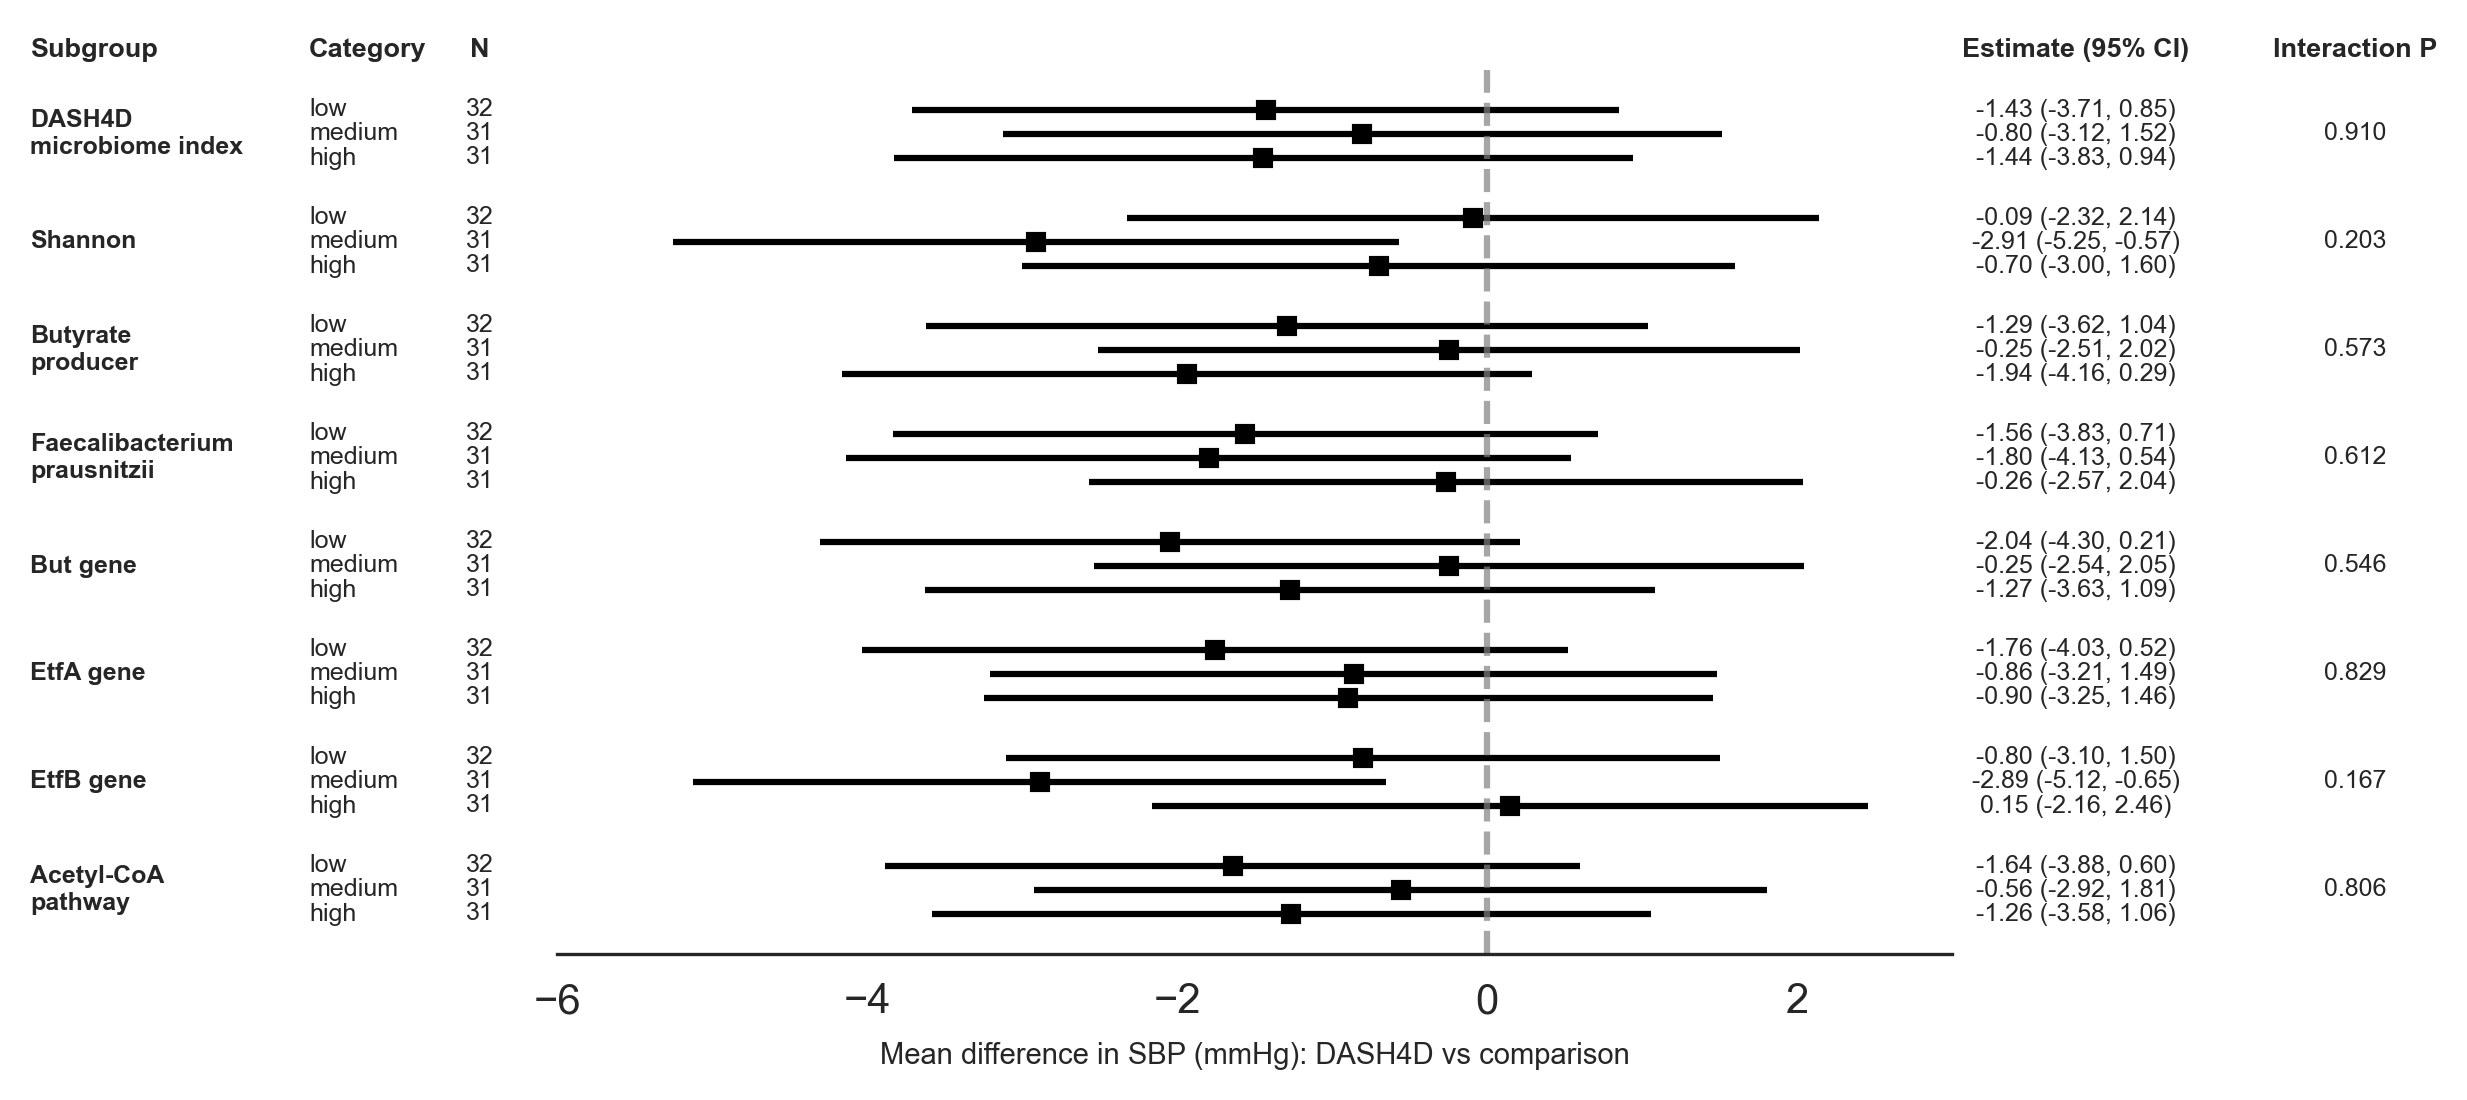

In [65]:
forest_plot_subgroup(
    change_SBP_bybaselinegp3_microbe,
    group_centers_SBPgp3,
    "Mean difference in SBP (mmHg): DASH4D vs comparison",
    f"{PAPER_FIG}/figS7",
    figure_size=(6,4),
    dpi=300,
    group_multi=1.1,
    var_multi=1.8,
    p_multi=1.8
)

#### Figure S8 — Fructosamine

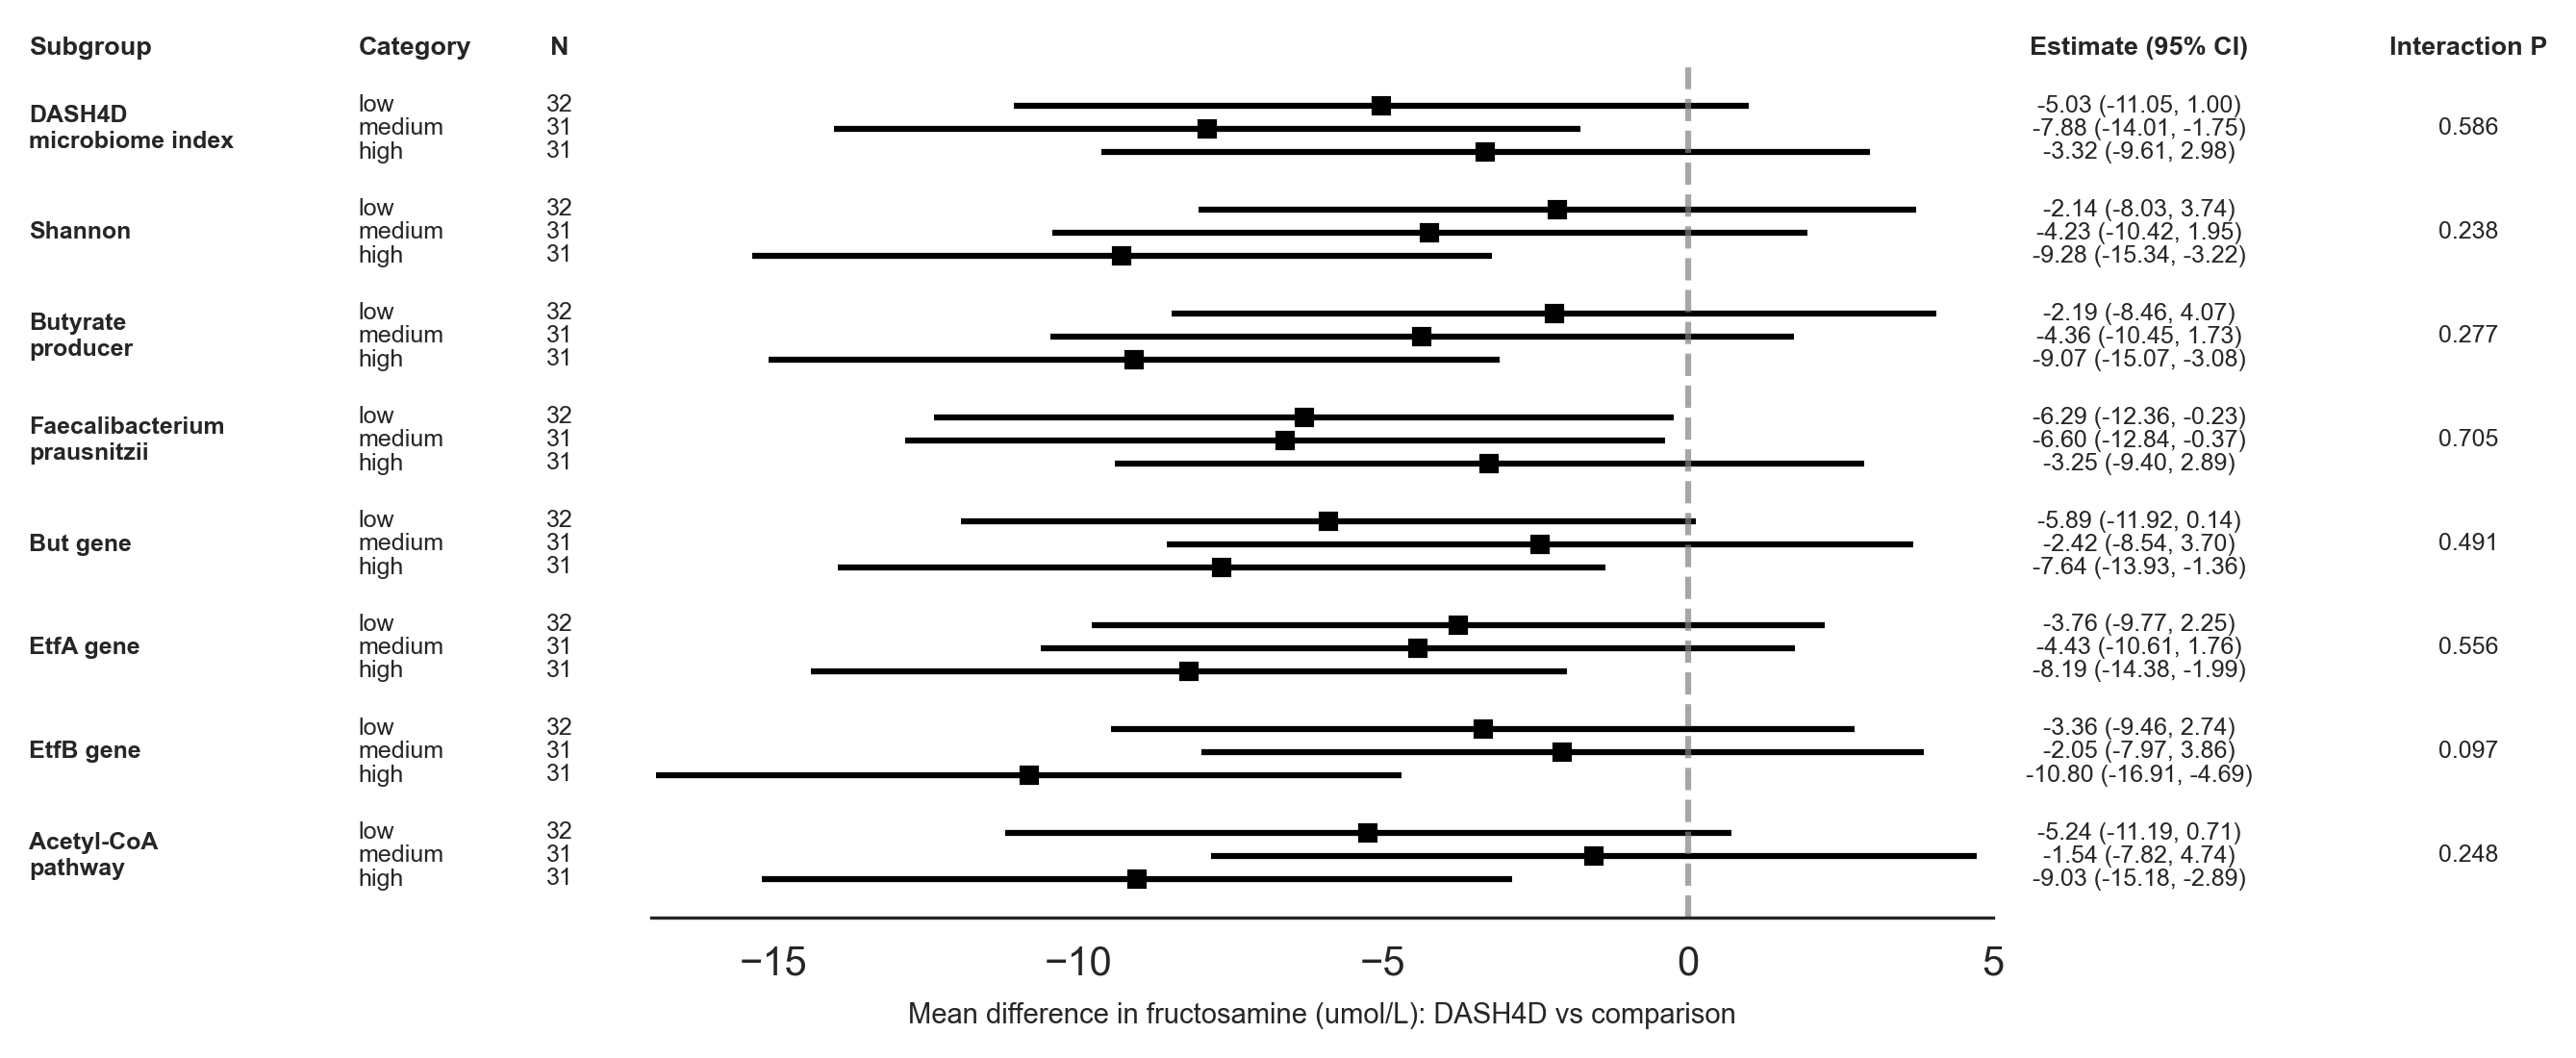

In [66]:
forest_plot_subgroup(
    change_fructosamine_bybaselinegp3_microbe,
    group_centers_fructosaminegp3,
    "Mean difference in fructosamine (umol/L): DASH4D vs comparison",
    f"{PAPER_FIG}/figS8",
    figure_size=(6,4),
    dpi=300,
    group_multi=1.1,
    var_multi=1.8,
    p_multi=1.8
)

#### Figure S9 — Fasting glucose

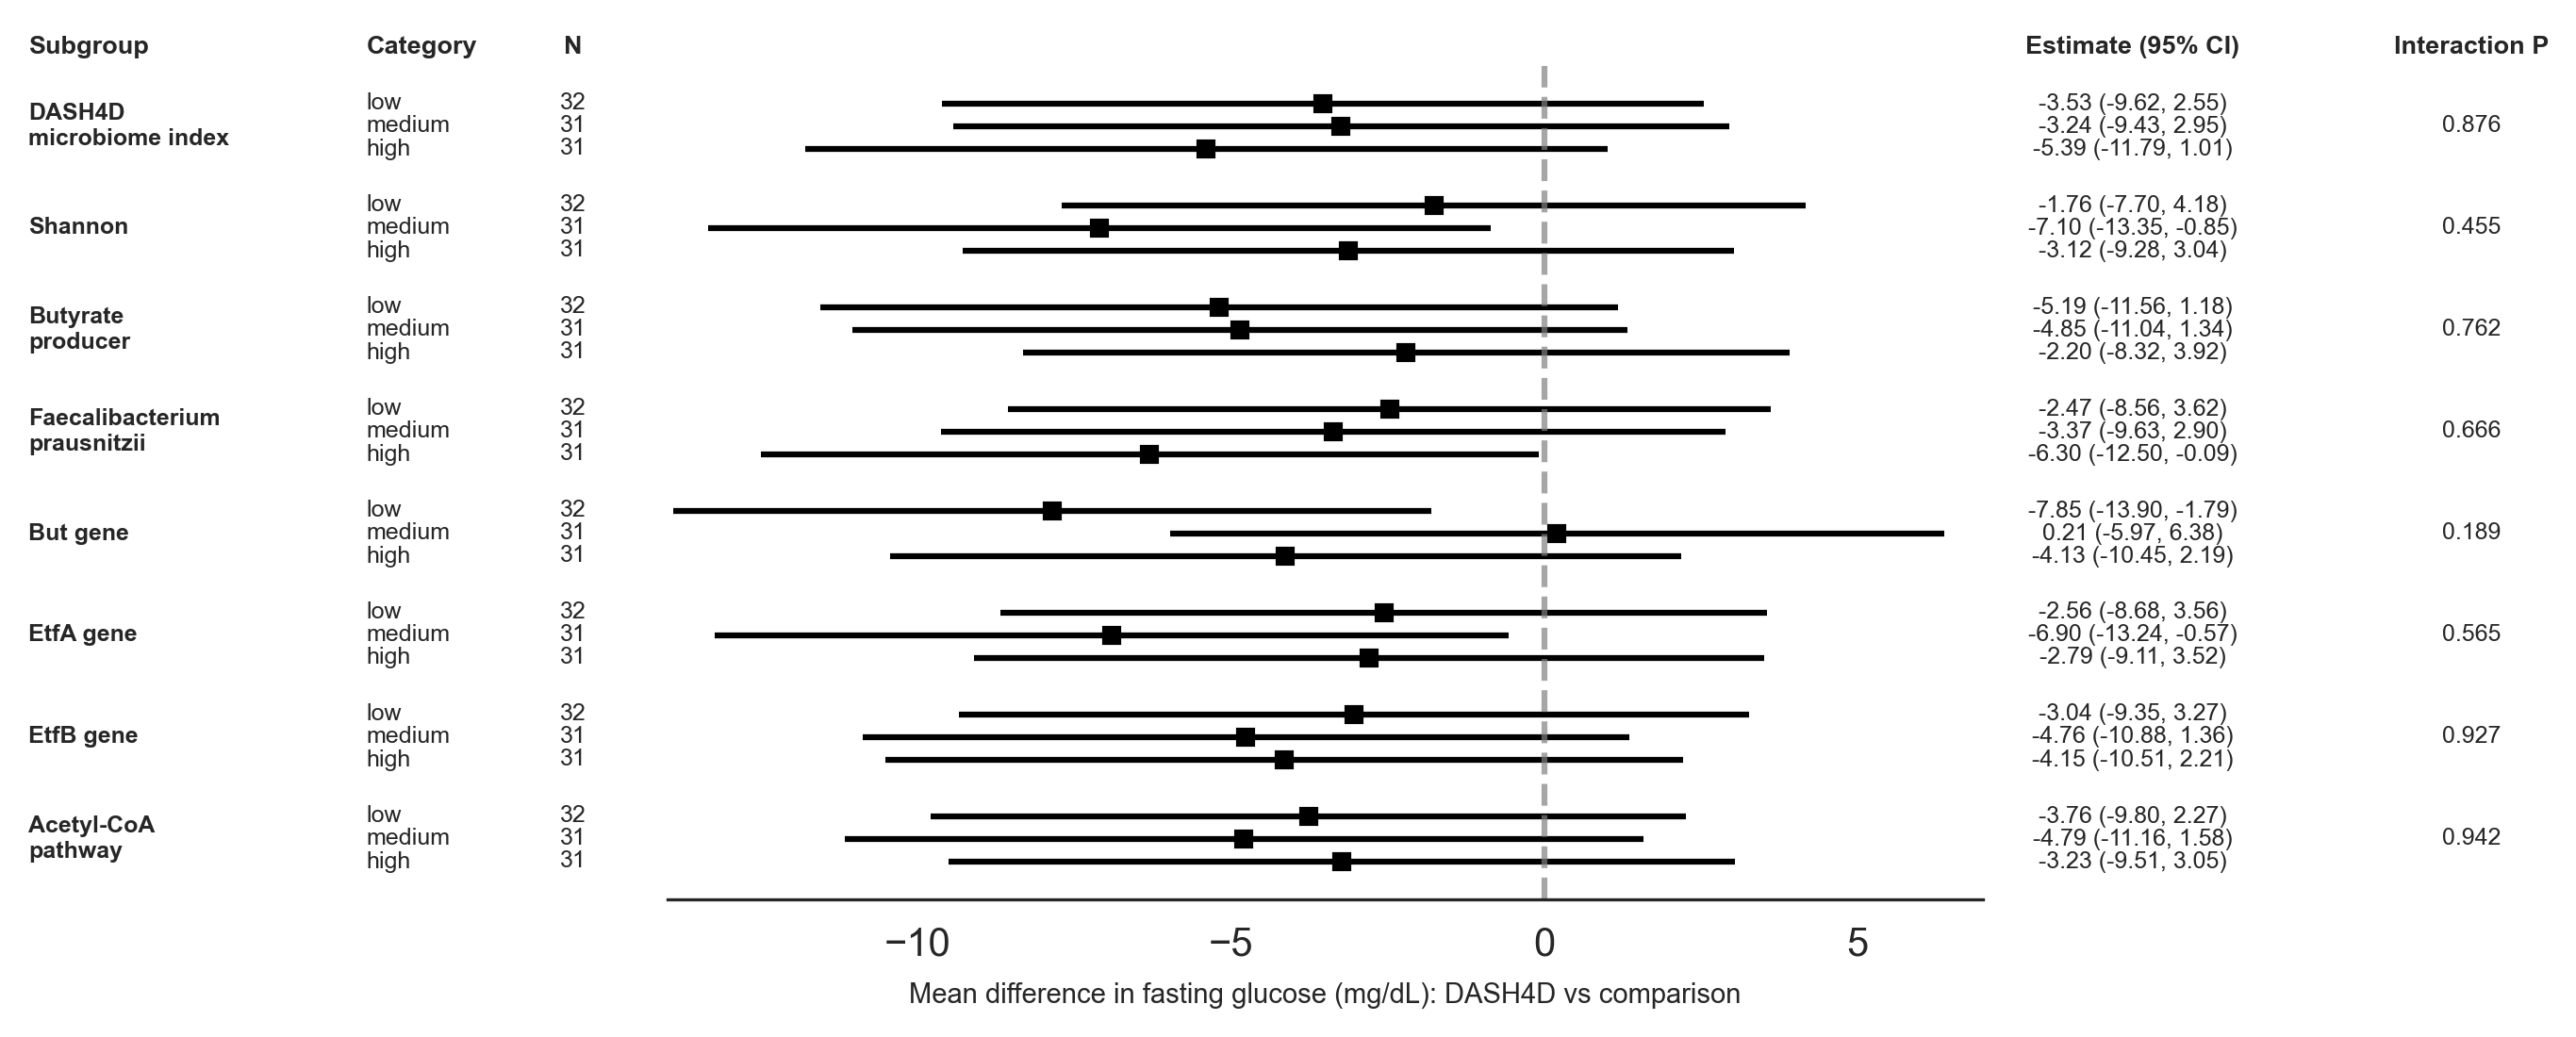

In [67]:
forest_plot_subgroup(
    change_fb_glucose_bybaselinegp3_microbe,
    group_centers_fb_glucosegp3,
    "Mean difference in fasting glucose (mg/dL): DASH4D vs comparison",
    f"{PAPER_FIG}/figS9",
    figure_size=(6,4),
    dpi=300,
    group_multi=1.1,
    var_multi=1.8,
    p_multi=1.8
)

#### Figure S10 — HOMA-IR

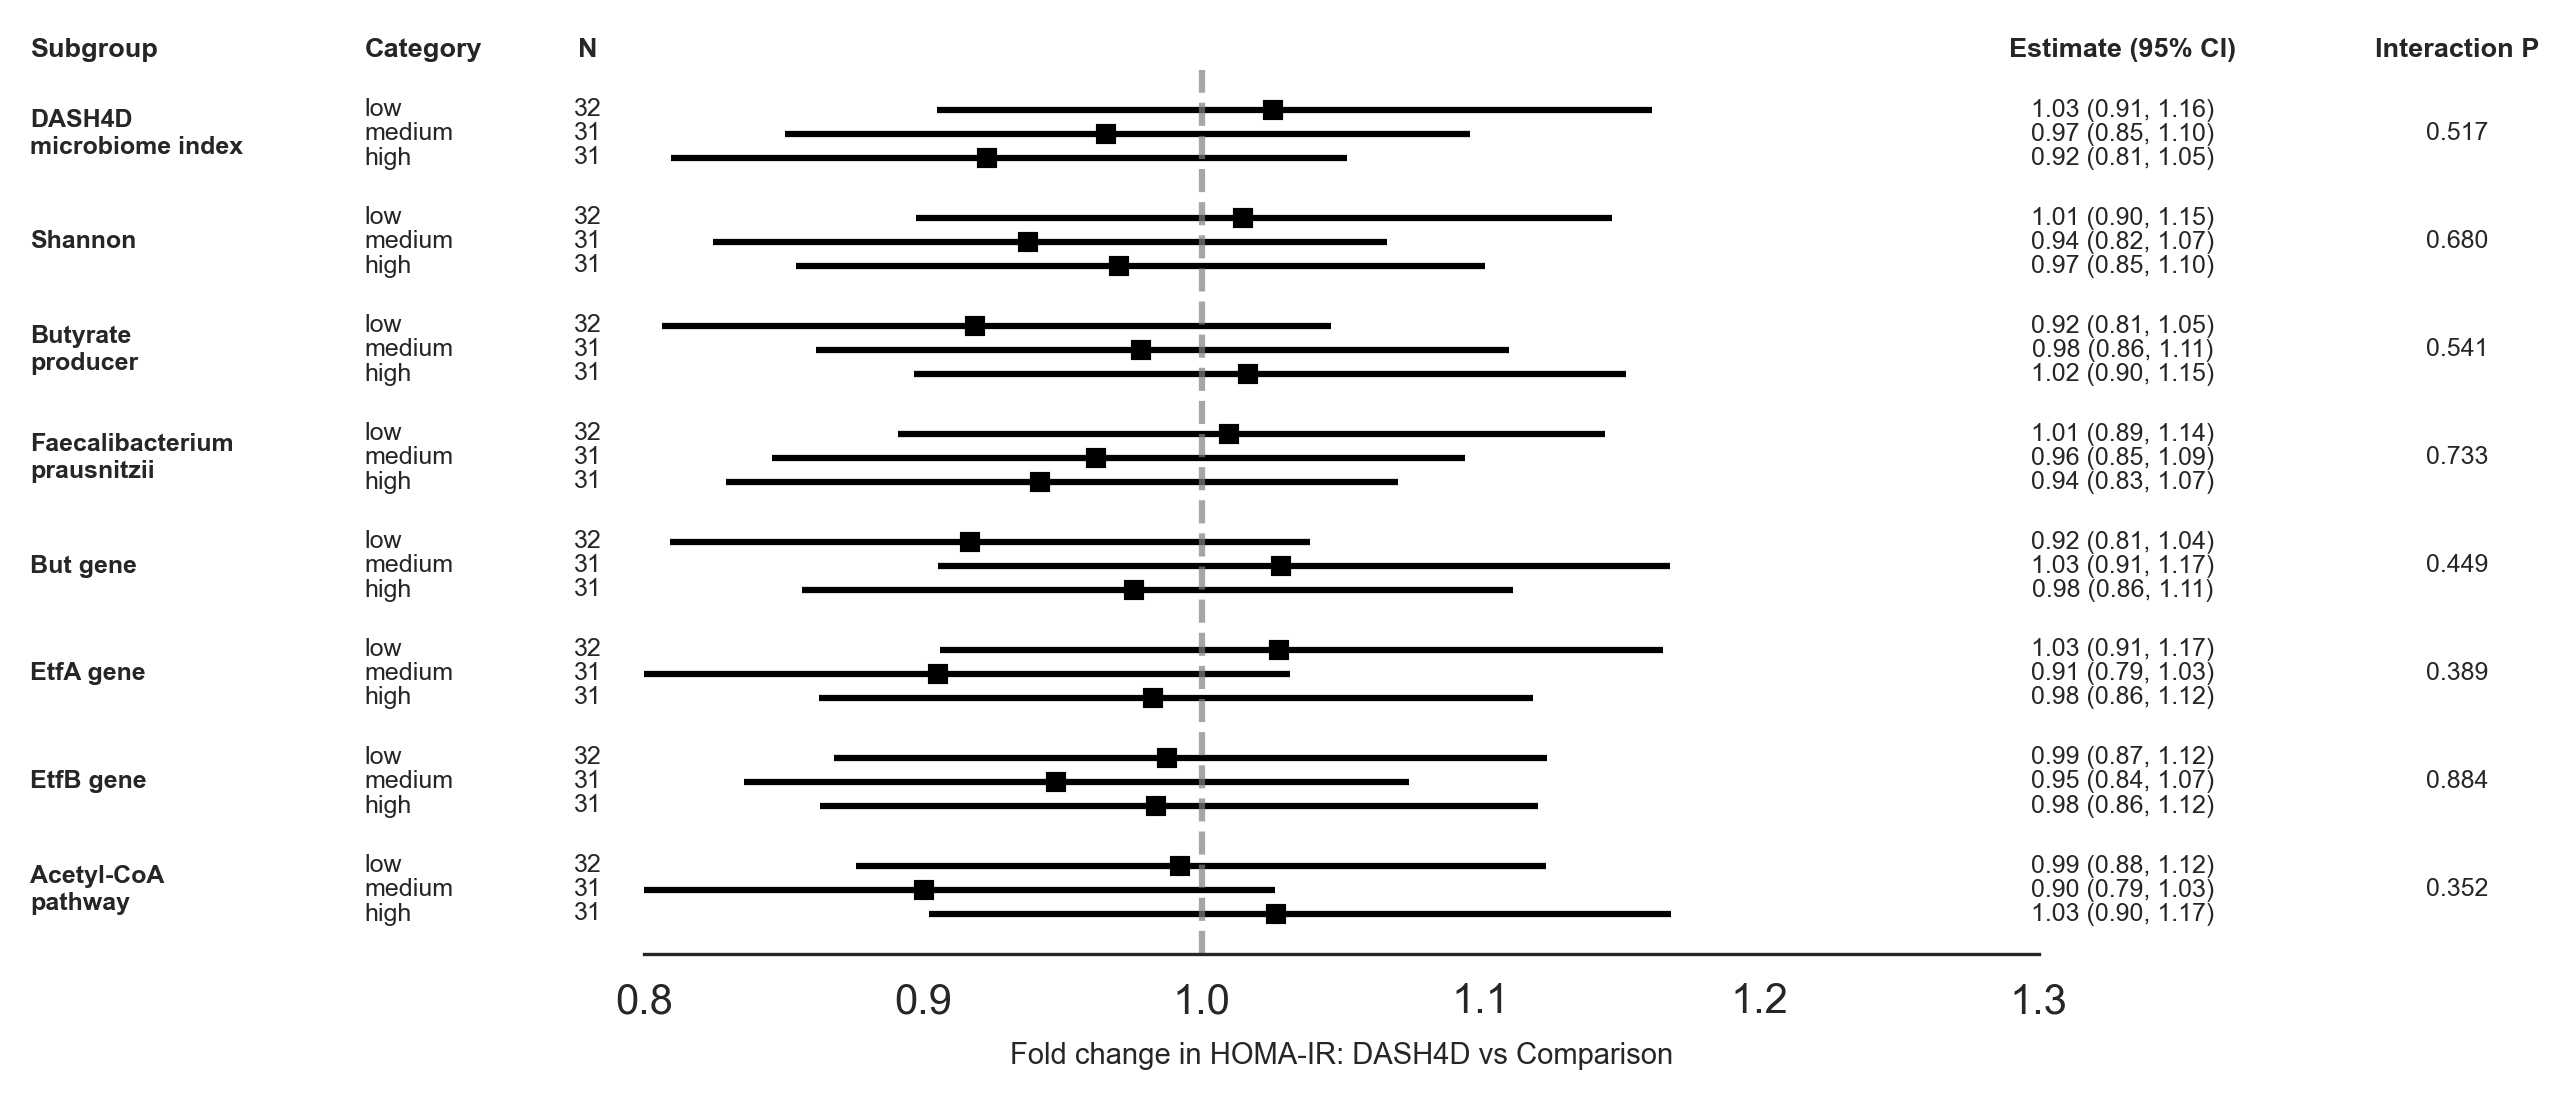

In [68]:
forest_plot_subgroup(
    change_log_HOMA_IR_bybaselinegp3_microbe,
    group_centers_log_HOMR_IRgp3,
    "Fold change in HOMA-IR: DASH4D vs Comparison",
    f"{PAPER_FIG}/figS10",
    figure_size=(6,4),
    dpi=300,
    null_line=1,
    customize_param={
        'left_x': 0.80,
        'right_x': 1.30,
        'pos_n': 0.78,
        'pos_group': 0.70,
        'pos_var': 0.58,
        'pos_est_text': 1.33,
        'pos_p': 1.45,
        'x_axis_tick_label':[0.80,0.90,1.00,1.10,1.20,1.30]
    }
)

In [69]:
# Output directory
env_dir = Path("../environment")
env_dir.mkdir(parents=True, exist_ok=True)

# Python and system information
with open(env_dir / "Python_environment.txt", "w") as f:
    f.write(f"Python version: {sys.version}\n")
    f.write(f"Operating system: {platform.platform()}\n")

# Packages used in this notebook
packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn"
]

# Export package versions
with open(env_dir / "Python_requirements.txt", "w") as f:
    for pkg in sorted(packages):
        f.write(f"{pkg}=={version(pkg)}\n")

# Export Python environment information
with open(env_dir / "Python_environment.txt", "w") as f:
    f.write(f"Python version: {platform.python_version()}\n")
    f.write(f"Operating system: {platform.system()}\n")
    f.write(f"Architecture: {platform.machine()}\n")